# 제주 통과형 동 v5 통합 분석
v4(EDA·STEP2~3)와 제주.ipynb(미스매치 신뢰성 검증)를 하나의 흐름으로 합친 최종 분석본.

흐름: 데이터 점검 → 관광 카테고리 정리 → **통과형 판정(9개 정의 합의)** → **1차 군집(환경 변수만)** → 군집 내 타깃·벤치마킹 선정 → 타깃 심층 진단 → **2026 상반기 사후 검증** → 기대효과 시나리오

- 분석 기간: 2023.01~2025.12 (36개월), 검증 기간: 2026.01~2026.06 (인기장소 데이터는 2025.12까지라 검증엔 트래픽·방문객·소비만 사용)
- 데이터 위치: `data/` (분석), `data/검증_2026H1/` (검증). 환경변수 `JEJU_DATA_DIR`로 바꿀 수 있음

## 0. 설정

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')
_avail = {f.name for f in font_manager.fontManager.ttflist}
for _f in ('Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR'):
    if _f in _avail:
        plt.rcParams['font.family'] = _f
        break
plt.rcParams['axes.unicode_minus'] = False
pd.options.display.float_format = '{:,.2f}'.format
pd.options.display.width = 220

DATA_DIR = os.environ.get('JEJU_DATA_DIR', 'data')
HOLD_DIR = os.path.join(DATA_DIR, '검증_2026H1')
OUT_DIR = os.environ.get('JEJU_OUT_DIR', os.path.join('outputs', 'v5'))
os.makedirs(OUT_DIR, exist_ok=True)
SEED = 42
rng = np.random.default_rng(SEED)

def save(fig, name):
    fig.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches='tight')

## 1. 데이터 불러오기와 점검

In [2]:
def read(path, **kw):
    for enc in ('utf-8-sig', 'cp949'):
        try:
            return pd.read_csv(path, encoding=enc, **kw)
        except UnicodeDecodeError:
            continue
    raise ValueError(path)

def prep(df):
    df = df.copy()
    df.columns = [c.replace(' ', '') for c in df.columns]
    ym = [c for c in df.columns if '연월' in c or '주행일자' in c][0]
    df['월'] = df[ym].astype(int)
    return df

def load_core(d):
    c = prep(read(os.path.join(d, '제주 지역별 차량 도착 수.csv'))).rename(columns={'도착건수': '차량도착'})
    v = prep(read(os.path.join(d, '제주 지역별 방문객.csv')))
    v = v.rename(columns={[x for x in v.columns if x.startswith('총방문객수')][0]: '총방문',
                          '내국인방문객수': '내국인방문', '외국인방문객수': '외국인방문'})
    s = prep(read(os.path.join(d, '제주 지역별 소비 데이터.csv'))).rename(columns={'소비금액(원)': '소비금액'})
    return c, v, s

c, v, s = load_core(DATA_DIR)
p = prep(read(os.path.join(DATA_DIR, '제주 지역별 인기 장소.csv')))
p = p.rename(columns={'카테고리3단계': '카테고리', '관광객도착수': '관광객도착', '도민도착수': '도민도착'})

DONGS = sorted(c['읍면동명'].unique())
for name, d in {'차량도착': c, '방문객': v, '소비': s, '인기장소': p}.items():
    print(f"[{name}] {d.shape} | {d['월'].min()}~{d['월'].max()} ({d['월'].nunique()}개월) | 동 {d['읍면동명'].nunique()}개")
    assert set(d['읍면동명']) == set(DONGS) and d['월'].nunique() == 36
print('관광객구분:', s['관광객구분'].unique().tolist(), '| 업종:', s['업종명'].unique().tolist())
area = s[['읍면동명', '지역명']].drop_duplicates().set_index('읍면동명')['지역명']

[차량도착] (1548, 5) | 202301~202512 (36개월) | 동 43개
[방문객] (1548, 9) | 202301~202512 (36개월) | 동 43개
[소비] (319123, 9) | 202301~202512 (36개월) | 동 43개


[인기장소] (846064, 10) | 202301~202512 (36개월) | 동 43개


관광객구분: ['도민', '내국인 관광객', '외국인 관광객'] | 업종: ['소매업', '숙박업', '음식점업', '기타서비스업', '예술스포츠여가업']


## 2. 관광 카테고리 정리
인기장소 카테고리 542개를 **관광지 / 로컬 소비처 / 숙박 / 대형쇼핑 / 이동·생활(비관광)** 으로 명시적으로 분류.
v4의 식도락 정규식은 `회`가 '구의회·상공회의소·사회단체' 등까지 잡아서 목록 기반으로 바꿈. 분류표는 `카테고리_분류표.csv`로 저장해 팀이 검토할 수 있게 함.

In [3]:
GROUPS = {
    '트레킹·자연': ['오름', '명산', '폭포/계곡', '자연휴양림', '공원', '도립공원', '국립공원', '전망대', '드라이브코스',
                 '산림욕장', '동굴', '섬', '해수욕장', '포구', '등대', '캠프장'],
    '관광명소':   ['관광명소기타', '관광단지', '박물관/기념관', '미술관', '전시장', '화랑/전시관', '동식물원', '수족관',
                 '테마파크', '문화유적지', '고택/생가/민속마을', '공연장', '축제', '절', '온천', '종합위락시설'],
    '체험·레저':  ['체험농가', '체험학습', '승마장', '낚시', '수상해양스포츠', '관광농원', '목장', '농장/농원',
                 '레저/스포츠기타', '여행/레저기타', '카레이싱장', '사격장'],
    '식도락':     ['한식', '전문음식점', '분식', '패스트푸드', '일식', '중식', '치킨', '세계요리', '부페', '음식료업',
                 '술집기타', '민속주점', '일본선술집', '음식점기타', '음식료기타', '시설내 음식점', '배달음식점'],
    '카페·디저트': ['카페기타', '커피전문점', '제과점', '테마카페', '이색카페', '음악카페', '떡/한과'],
    '로드샵·로컬': ['재래시장', '시장기타', '농수축산물점', '특산물단지', '공방/공예', '꽃집', '서점/책방', '쇼핑기타'],
    '숙박':       ['호텔', '콘도/리조트', '펜션', '게스트하우스', '민박', '모텔/여관', '숙박기타'],
    '대형쇼핑':    ['대형마트', '대형슈퍼', '면세점', '신세계프리미엄아울렛', '다이소', '할인점'],
}
ATTR_G = ['트레킹·자연', '관광명소', '체험·레저']
LOCAL_G = ['식도락', '카페·디저트', '로드샵·로컬']
cat2g = {cat: g for g, cats in GROUPS.items() for cat in cats}
p['그룹'] = p['카테고리'].map(cat2g).fillna('이동·생활·기타')

cat_tbl = (p.groupby(['그룹', '카테고리'])['관광객도착'].sum().reset_index()
             .sort_values(['그룹', '관광객도착'], ascending=[True, False]))
cat_tbl.to_csv(os.path.join(OUT_DIR, '카테고리_분류표.csv'), index=False, encoding='utf-8-sig')
share = p.groupby('그룹')['관광객도착'].sum() / p['관광객도착'].sum()
print('관광객 도착 중 그룹별 비중:\n', (share * 100).round(1).sort_values(ascending=False).to_string())
print('\n분류 안 된 카테고리 중 관광객 도착 상위 15 (빠진 관광지가 없는지 확인용):')
print(cat_tbl[cat_tbl['그룹'] == '이동·생활·기타'].head(15)[['카테고리', '관광객도착']].to_string(index=False))

관광객 도착 중 그룹별 비중:
 그룹
식도락        21.80
이동·생활·기타   21.40
숙박         16.00
카페·디저트     11.30
트레킹·자연      9.90
관광명소        9.50
로드샵·로컬      4.00
대형쇼핑        3.60
체험·레저       2.60

분류 안 된 카테고리 중 관광객 도착 상위 15 (빠진 관광지가 없는지 확인용):
    카테고리  관광객도착
     렌트카 801901
      공항 526191
     주차장 414403
      항구 372653
     주유소 244292
     골프장 217830
   아파트단지 108246
  전기차충전소 105721
   가스충전소 103684
     편의점  87964
일반/국도휴게소  74685
      의원  72922
슈퍼/마트 기타  69904
      빌라  62144
      약국  59984


## 3. 동 단위 지표

In [4]:
st = s[s['관광객구분'] != '도민']
BIZ = sorted(s['업종명'].unique())
biz = st.pivot_table(index='읍면동명', columns='업종명', values='소비금액', aggfunc='sum', fill_value=0)

def place_count(groups):
    q = p[p['그룹'].isin(groups)].drop_duplicates(['목적지명', '목적지주소'])
    return q.groupby('읍면동명').size()

pg = p.pivot_table(index='읍면동명', columns='그룹', values='관광객도착', aggfunc='sum', fill_value=0)
D = pd.DataFrame(index=DONGS)
D['시'] = area.reindex(DONGS).str.split().str[0]
D['권역'] = area.reindex(DONGS)
D['차량도착'] = c.groupby('읍면동명')['차량도착'].sum()
D['총방문'] = v.groupby('읍면동명')['총방문'].sum()
D['외국인방문'] = v.groupby('읍면동명')['외국인방문'].sum()
D['관광객소비'] = st.groupby('읍면동명')['소비금액'].sum()
D['관광객소비_숙박제외'] = D['관광객소비'] - biz.get('숙박업', 0)
D['외국인소비'] = s[s['관광객구분'] == '외국인 관광객'].groupby('읍면동명')['소비금액'].sum()
D['도민소비'] = s[s['관광객구분'] == '도민'].groupby('읍면동명')['소비금액'].sum()
D['관광객도착_전체'] = p.groupby('읍면동명')['관광객도착'].sum()
D['도착건수_전체'] = p.groupby('읍면동명')['도착건수'].sum()
D['관광지_관광객도착'] = pg[ATTR_G].sum(axis=1)
D['로컬_관광객도착'] = pg[LOCAL_G].sum(axis=1)
D['관광객비중'] = D['관광객도착_전체'] / D['도착건수_전체']
D['트레킹비중'] = pg['트레킹·자연'] / D['관광객도착_전체']
D['관광명소비중'] = pg['관광명소'] / D['관광객도착_전체']
D['체험비중'] = pg['체험·레저'] / D['관광객도착_전체']
D['관광지수'] = place_count(ATTR_G)
D['로컬소비처수'] = place_count(LOCAL_G)
D['숙박시설수'] = place_count(['숙박'])
D = D.fillna({'관광지수': 0, '로컬소비처수': 0, '숙박시설수': 0, '외국인소비': 0})
D['로컬전환비'] = D['로컬_관광객도착'] / D['관광지_관광객도착']
D['외국인방문비중'] = D['외국인방문'] / D['총방문']
D['외국인소비비중'] = D['외국인소비'] / D['관광객소비']
D['숙박업비중'] = biz.get('숙박업', 0) / D['관광객소비']

# 관광 동: 도민 생활 이동이 대부분인 동(관광객비중 < 0.4)과 접근 수단이 배인 도서(추자·우도)는 통과형 판정에서 제외
TOUR_MIN = 0.4
ISLANDS = ['추자면', '우도면']
D['관광동'] = (D['관광객비중'] >= TOUR_MIN) & ~D.index.isin(ISLANDS)
print('관광 동', D['관광동'].sum(), '개 | 생활권 제외:', D.index[D['관광객비중'] < TOUR_MIN].tolist(), '| 도서 제외:', ISLANDS)
print('\n숙박업 카드소비 비중이 1% 미만인 동(온라인 선결제로 카드 데이터에 숙박비가 거의 안 잡힘):',
      D.index[D['숙박업비중'] < 0.01].tolist())

관광 동 28 개 | 생활권 제외: ['노형동', '동홍동', '삼도1동', '삼양동', '서홍동', '아라동', '연동', '오라동', '외도동', '이도1동', '이도2동', '일도2동', '화북동'] | 도서 제외: ['추자면', '우도면']

숙박업 카드소비 비중이 1% 미만인 동(온라인 선결제로 카드 데이터에 숙박비가 거의 안 잡힘): ['동홍동', '서홍동', '아라동', '용담2동', '우도면', '일도1동', '일도2동', '한경면', '화북동', '효돈동']


### 3-1. 배경 검증: 데이터로 본 2023→2025 제주 관광의 변화
실태조사(설문)의 흐름이 내비·카드·통신 데이터에서도 보이는지 확인한다. 데이터와 다른 배경 문장은 고쳐 쓴다.

[연도별 총량]
          차량도착   SKT관광객방문  관광지_관광객도착     관광객소비_숙박제외    관광지도착당_소비    방문당_소비
월                                                                         
2023  17014200  158010994    2017330  2328489979391 1,154,243.47 14,736.25
2024  15133001  162912218    1648361  2332172609065 1,414,843.36 14,315.52
2025  13890259  155273530    1433372  2218169279876 1,547,518.22 14,285.56

[전년 대비 %]
       차량도착  SKT관광객방문  관광지_관광객도착  관광객소비_숙박제외  관광지도착당_소비  방문당_소비
월                                                              
2024 -11.10      3.10     -18.30        0.20      22.60   -2.90
2025  -8.20     -4.70     -13.00       -4.90       9.40   -0.20



[관광객 목적지 구성비 %]
그룹    트레킹·자연  관광명소  체험·레저   식도락  카페·디저트  로드샵·로컬  대형쇼핑
월                                                    
2023   10.00  9.70   2.70 22.10   10.90    3.90  3.10
2024    9.90  9.40   2.60 21.70   11.40    3.90  3.90
2025    9.70  9.30   2.40 21.40   11.90    4.00  4.10



2023→2025 차량 도착이 늘어난 동: 8개 / 43개 → {'추자면': 1.47, '아라동': 0.1, '외도동': 0.09, '화북동': 0.05, '이도1동': 0.04, '오라동': 0.03, '삼양동': 0.01, '삼도1동': 0.01}

→ 전체 이동량은 줄었지만 도착 1건당 소비는 늘었다: "더 많이 오게" 보다 "온 사람을 소비로 전환"하는 전략의 가치가 커지는 국면


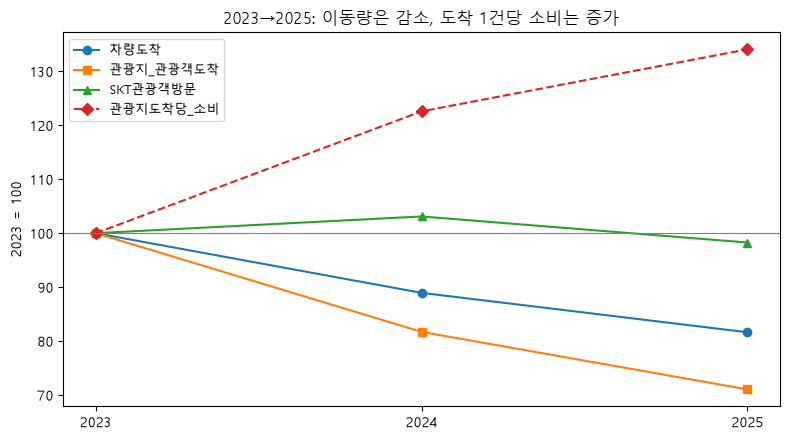

In [5]:
yr_tbl = pd.DataFrame({
    '차량도착': c.groupby(c['월'] // 100)['차량도착'].sum(),
    'SKT관광객방문': v.groupby(v['월'] // 100)['총방문'].sum(),
    '관광지_관광객도착': p[p['그룹'].isin(ATTR_G)].groupby(p['월'] // 100)['관광객도착'].sum(),
    '관광객소비_숙박제외': st[st['업종명'] != '숙박업'].groupby(st['월'] // 100)['소비금액'].sum(),
})
yr_tbl['관광지도착당_소비'] = yr_tbl['관광객소비_숙박제외'] / yr_tbl['관광지_관광객도착']
yr_tbl['방문당_소비'] = yr_tbl['관광객소비_숙박제외'] / yr_tbl['SKT관광객방문']
print('[연도별 총량]'); print(yr_tbl.to_string())
print('\n[전년 대비 %]'); print((yr_tbl.pct_change() * 100).dropna().round(1).to_string())
grp_y = p.pivot_table(index=p['월'] // 100, columns='그룹', values='관광객도착', aggfunc='sum')
print('\n[관광객 목적지 구성비 %]'); print((grp_y.div(grp_y.sum(axis=1), axis=0) * 100).round(1)[ATTR_G + LOCAL_G + ['대형쇼핑']].to_string())
dyr = c.pivot_table(index='읍면동명', columns=c['월'] // 100, values='차량도착', aggfunc='sum')
up = (dyr[2025] / dyr[2023] - 1).sort_values(ascending=False)
print(f'\n2023→2025 차량 도착이 늘어난 동: {(up > 0).sum()}개 / 43개 →', up[up > 0].round(2).to_dict())
print('\n→ 전체 이동량은 줄었지만 도착 1건당 소비는 늘었다: "더 많이 오게" 보다 "온 사람을 소비로 전환"하는 전략의 가치가 커지는 국면')

fig, ax = plt.subplots(figsize=(8, 4.5))
idx = yr_tbl / yr_tbl.loc[2023] * 100
for col_, st_ in [('차량도착', '-o'), ('관광지_관광객도착', '-s'), ('SKT관광객방문', '-^'), ('관광지도착당_소비', '--D')]:
    ax.plot(idx.index.astype(str), idx[col_], st_, label=col_)
ax.axhline(100, color='gray', lw=0.8); ax.set_ylabel('2023 = 100'); ax.legend(fontsize=9)
ax.set_title('2023→2025: 이동량은 감소, 도착 1건당 소비는 증가')
plt.tight_layout(); save(fig, '00_배경_연도추이.png'); plt.show()

## 4. 통과형 판정: 9개 정의의 합의
피드백 3(미스매치 지수 신뢰성)에 대한 답. 한 가지 공식 대신 **트래픽 3종 × 계산법 3종 = 9개 정의**로 '트래픽 대비 소비 부족'을 측정하고, 대부분의 정의에서 공통으로 하위권인 동만 통과형으로 본다.

- 트래픽: ① 티맵 차량 도착(전체) ② 티맵 관광지 관광객 도착 ③ SKT 관광객 방문(30분 이상 체류)
- 소비: 관광객(내·외국인) 카드 소비, **숙박업 제외** (숙박비는 온라인 선결제가 많아 동별로 잡히는 정도가 들쭉날쭉함)
- 계산법: (a) 로그 회귀잔차 (b) 로그 Z 차이 (c) 백분위 순위 차이 — 모두 규모 편향이 적은 방식 (원안 Z 차이는 큰 동이 무조건 높게 나오는 문제가 있어 제외하고 비교용으로만 계산)
- 부호: 모든 지표를 **'소비 부족 점수'**(클수록 트래픽 대비 소비가 부족)로 통일

In [6]:
TRAFFIC = {'차량': '차량도착', '관광지관광객': '관광지_관광객도착', 'SKT방문': '총방문'}
SPEND = '관광객소비_숙박제외'

def gap_scores(df, tcol, scol):
    lx, ly = np.log(df[tcol]), np.log(df[scol])
    b, a = np.polyfit(lx, ly, 1)
    z = lambda x: (x - x.mean()) / x.std()
    return {
        '잔차': -(ly - (a + b * lx)),
        '로그Z차': z(lx) - z(ly),
        '순위차': lx.rank(pct=True) - ly.rank(pct=True),
    }

def all_scores(df):
    out = {}
    for tn, tc in TRAFFIC.items():
        for mn, sc in gap_scores(df, tc, SPEND).items():
            out[f'{tn}_{mn}'] = sc
    return pd.DataFrame(out)

T = D[D['관광동']].copy()
SC = all_scores(T)
Zs = (SC - SC.mean()) / SC.std()
T['합의점수'] = Zs.mean(axis=1)
TOPK = 8
T['상위K_정의수'] = (SC.rank(ascending=False) <= TOPK).sum(axis=1)

# 원안(차량 Z 차이, 관광객소비 전체) - 비교용
raw_z = lambda x: (x - x.mean()) / x.std()
T['원안MI'] = raw_z(T['차량도착']) - raw_z(T['관광객소비'])

print(f'정의 간 순위 상관(스피어만) 평균: {SC.corr("spearman").values[np.triu_indices(9, 1)].mean():.2f}')
print(f'규모 편향(트래픽 규모와의 상관): 원안 {stats.spearmanr(T["차량도착"], T["원안MI"])[0]:.2f}'
      f' vs 합의점수 {stats.spearmanr(T["차량도착"], T["합의점수"])[0]:.2f}')

정의 간 순위 상관(스피어만) 평균: 0.61
규모 편향(트래픽 규모와의 상관): 원안 0.61 vs 합의점수 -0.30


### 4-1. 안정성 점검: 월 부트스트랩 + 연도별 재계산

In [7]:
def month_panel():
    m = pd.DataFrame(index=pd.MultiIndex.from_product([sorted(c['월'].unique()), DONGS], names=['월', '읍면동명']))
    m['차량도착'] = c.groupby(['월', '읍면동명'])['차량도착'].sum()
    m['총방문'] = v.groupby(['월', '읍면동명'])['총방문'].sum()
    m['관광지_관광객도착'] = p[p['그룹'].isin(ATTR_G)].groupby(['월', '읍면동명'])['관광객도착'].sum()
    stx = st[st['업종명'] != '숙박업']
    m[SPEND] = stx.groupby(['월', '읍면동명'])['소비금액'].sum()
    return m.fillna(0)

MP = month_panel()
months = MP.index.get_level_values(0).unique()
tour_idx = T.index

def consensus_from(mp_sub):
    agg = mp_sub.groupby(level='읍면동명').sum().loc[tour_idx]
    sc = all_scores(agg)
    return ((sc - sc.mean()) / sc.std()).mean(axis=1)

N_BOOT = int(os.environ.get("JEJU_NBOOT", 1000))
boot_top = pd.Series(0.0, index=tour_idx)
boot_rank = []
for _ in range(N_BOOT):
    pick = rng.choice(months, size=len(months), replace=True)
    sub = pd.concat([MP.xs(mo, level='월', drop_level=False) for mo in pick])
    cs = consensus_from(sub)
    boot_top += (cs.rank(ascending=False) <= TOPK)
    boot_rank.append(cs.rank(ascending=False))
T['부트스트랩_상위K확률'] = boot_top / N_BOOT

yr = {}
for y in (2023, 2024, 2025):
    yr[y] = consensus_from(MP[MP.index.get_level_values(0) // 100 == y])
YR = pd.DataFrame(yr)
print('연도별 합의점수 순위 상관(스피어만):')
print(YR.corr('spearman').round(2).to_string())

T[[f'연도순위_{y}' for y in YR]] = YR.rank(ascending=False).astype(int).values
show = ['시', '관광객비중', '합의점수', '상위K_정의수', '부트스트랩_상위K확률', '연도순위_2023', '연도순위_2024', '연도순위_2025', '원안MI']
print(f'\n[합의점수 상위 12] (상위K={TOPK})')
print(T.sort_values('합의점수', ascending=False)[show].head(12).to_string())

연도별 합의점수 순위 상관(스피어만):
      2023  2024  2025
2023  1.00  0.94  0.73
2024  0.94  1.00  0.89
2025  0.73  0.89  1.00

[합의점수 상위 12] (상위K=8)
        시  관광객비중  합의점수  상위K_정의수  부트스트랩_상위K확률  연도순위_2023  연도순위_2024  연도순위_2025  원안MI
한경면   제주시   0.54  1.13        9         1.00          3          1          1  0.08
송산동  서귀포시   0.62  0.93        7         1.00          2          3          6 -0.23
효돈동  서귀포시   0.58  0.92        6         1.00          4          2          5 -0.20
봉개동   제주시   0.44  0.85        6         1.00          7          4          2 -0.27
천지동  서귀포시   0.61  0.66        5         1.00          6          6          8 -0.11
남원읍  서귀포시   0.53  0.66        6         0.98          8          5          7  0.06
대천동  서귀포시   0.44  0.59        4         0.94          9          7          4 -0.12
구좌읍   제주시   0.61  0.55        4         0.76          5          8         10  1.03
영천동  서귀포시   0.46  0.51        4         0.26         16         11          3 -0.18
대정읍  서귀포시   0.42  0.41  

### 4-2. 민감도: 기준을 바꿔도 같은 동이 나오나
숙박업 포함 여부, 상위 K(6/8/10), 이전 분석(v4 소비잔차, 제주.ipynb 9방식 합의)과 비교

In [8]:
def consensus_with(spend_col, df=T):
    out = {}
    for tn, tc in TRAFFIC.items():
        for mn, sc in gap_scores(df, tc, spend_col).items():
            out[f'{tn}_{mn}'] = sc
    sc = pd.DataFrame(out)
    return ((sc - sc.mean()) / sc.std()).mean(axis=1), sc

cons_incl, sc_incl = consensus_with('관광객소비')
sens = pd.DataFrame(index=T.index)
for k in (6, 8, 10):
    sens[f'숙박제외_K{k}'] = (SC.rank(ascending=False) <= k).sum(axis=1) >= 6
    sens[f'숙박포함_K{k}'] = (sc_incl.rank(ascending=False) <= k).sum(axis=1) >= 6
lx, ly = np.log(T['관광객도착_전체']), np.log(T['관광객소비'])
b_, a_ = np.polyfit(lx, ly, 1)
sens['v4_소비잔차<-0.3'] = (ly - (a_ + b_ * lx)) < -0.3
base_path = 'jeju_dong_base_table.csv'
if os.path.exists(base_path):
    bt = pd.read_csv(base_path, encoding='utf-8-sig').set_index('읍면동명')
    sens['제주ipynb_합의'] = bt['합의_통과형'].reindex(T.index).fillna(False).astype(bool)
sens['선정횟수'] = sens.sum(axis=1)
sens = sens[sens['선정횟수'] > 0].sort_values('선정횟수', ascending=False)
print(sens.astype(int).to_string())
N_CRIT = sens.shape[1] - 1
print(f'\n총 {N_CRIT}개 기준 중 과반에서 선정된 동:', sens.index[sens['선정횟수'] > N_CRIT / 2].tolist())

     숙박제외_K6  숙박포함_K6  숙박제외_K8  숙박포함_K8  숙박제외_K10  숙박포함_K10  v4_소비잔차<-0.3  제주ipynb_합의  선정횟수
한경면        1        1        1        1         1         1             1           1     8
효돈동        0        1        1        1         1         1             1           1     7
구좌읍        0        1        0        1         1         1             1           0     5
송산동        1        0        1        1         1         1             0           0     5
남원읍        0        0        1        1         1         1             0           0     4
천지동        0        0        0        0         1         1             1           1     4
도두동        0        0        0        1         0         1             0           0     2
봉개동        0        0        1        0         1         0             0           0     2
대천동        0        0        0        0         1         0             0           0     1
대정읍        0        0        0        0         0         1             0       

### 4-3. 최종 통과형 판정
두 조건을 모두 만족하는 동만 **강건한 통과형**으로 본다 (2026 데이터는 쓰지 않음 → 8장에서 사후 검증용으로 남겨둠)
1. 기준을 바꿔도 나온다: 민감도 기준 8개 중 과반에서 선정
2. 해마다 나온다: 2023·2024·2025 각 연도 합의점수 순위가 모두 상위 8위 이내

In [9]:
T['민감도_선정횟수'] = sens['선정횟수'].reindex(T.index).fillna(0).astype(int)
T['연도_모두상위'] = (T[[f'연도순위_{y}' for y in YR]] <= TOPK).all(axis=1)
T['통과형'] = (T['민감도_선정횟수'] > N_CRIT / 2) & T['연도_모두상위']
PASS = T.index[T['통과형']].tolist()
print(T.loc[T['민감도_선정횟수'] > 0, ['합의점수', '민감도_선정횟수', '연도순위_2023', '연도순위_2024', '연도순위_2025', '통과형']]
      .sort_values('합의점수', ascending=False).to_string())
print('\n▶ 강건한 통과형 동:', PASS)

     합의점수  민감도_선정횟수  연도순위_2023  연도순위_2024  연도순위_2025    통과형
한경면  1.13         8          3          1          1   True
송산동  0.93         5          2          3          6   True
효돈동  0.92         7          4          2          5   True
봉개동  0.85         2          7          4          2  False
천지동  0.66         4          6          6          8  False
남원읍  0.66         4          8          5          7  False
대천동  0.59         1          9          7          4  False
구좌읍  0.55         5          5          8         10  False
영천동  0.51         1         16         11          3  False
대정읍  0.41         1         11         12         12  False
도두동  0.36         2         14         10         11  False
성산읍  0.14         1         13         17         15  False

▶ 강건한 통과형 동: ['송산동', '한경면', '효돈동']


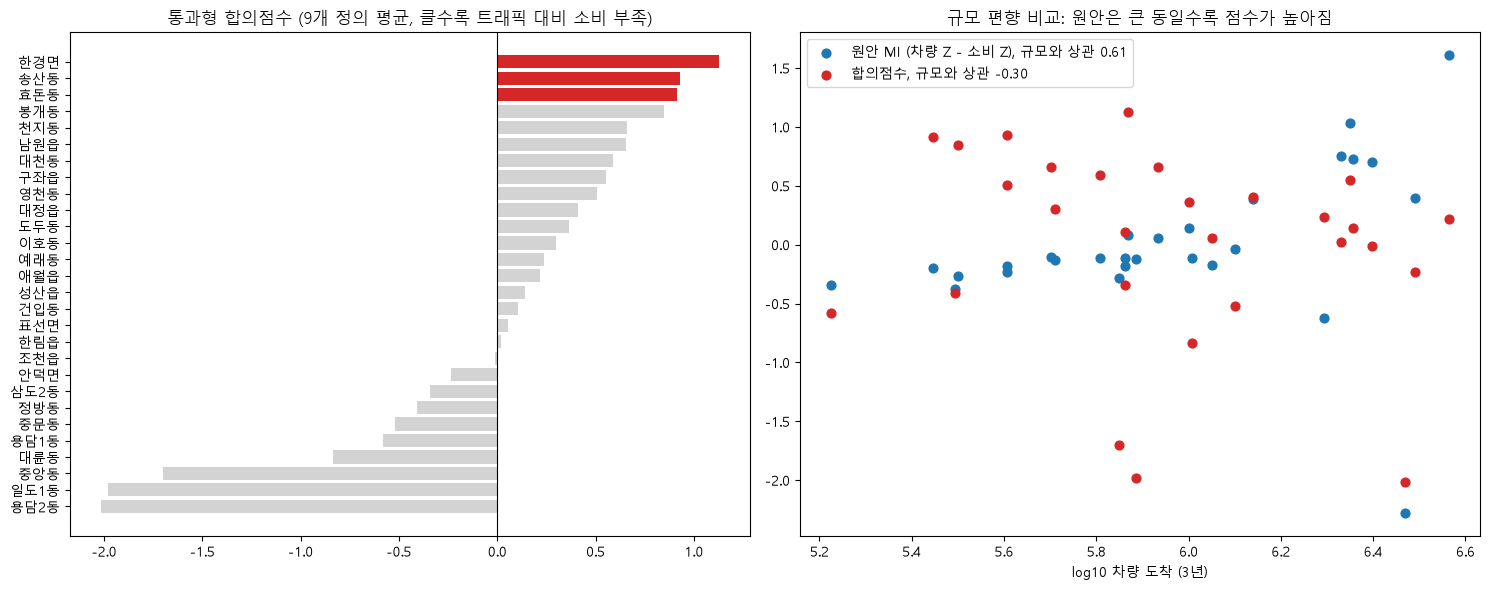

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
o = T.sort_values('합의점수')
ax[0].barh(o.index, o['합의점수'], color=np.where(o['통과형'], 'tab:red', 'lightgray'))
ax[0].set_title('통과형 합의점수 (9개 정의 평균, 클수록 트래픽 대비 소비 부족)')
ax[0].axvline(0, color='k', lw=0.8)
ax[1].scatter(np.log10(T['차량도착']), T['원안MI'], c='tab:blue', label=f'원안 MI (차량 Z - 소비 Z), 규모와 상관 {stats.spearmanr(T["차량도착"], T["원안MI"])[0]:.2f}', s=40)
ax[1].scatter(np.log10(T['차량도착']), T['합의점수'], c='tab:red', label=f'합의점수, 규모와 상관 {stats.spearmanr(T["차량도착"], T["합의점수"])[0]:.2f}', s=40)
ax[1].set_xlabel('log10 차량 도착 (3년)'); ax[1].legend()
ax[1].set_title('규모 편향 비교: 원안은 큰 동일수록 점수가 높아짐')
plt.tight_layout(); save(fig, '01_통과형_합의점수.png'); plt.show()

## 5. 1차 군집: 관광 환경 유형화 (소비·트래픽 제외)
중간발표 설계대로 **성과 변수(소비, 트래픽)는 넣지 않고** 관광 환경만으로 관광 동 28개를 유형화한다. 그래야 "같은 환경인데 소비 전환이 다른 동"을 비교할 수 있다.

변수 후보 4세트를 비교한 결과(아래 표), **공급규모 + 자연·체험 비중** 2개 축이 가장 뚜렷하고 안정적이었다.
- 공급규모: 관광지 수·로컬 소비처 수·숙박시설 수(log)의 표준화 평균. 세 변수는 서로 상관 0.69~0.89라 하나로 합침(다중공선성 대응)
- 자연·체험 비중: 관광객 도착 중 트레킹·자연 + 체험·레저 목적지 비중
- 2개 축이라 PCA 없이 원 변수 그대로 그림으로 보여줄 수 있어 해석이 쉬움 (6개 변수 + PCA 버전은 실루엣 0.21~0.27, 안정성 0.34~0.57로 구조가 약했음)

In [11]:
supply = pd.DataFrame({k: np.log1p(T[k]) for k in ['관광지수', '로컬소비처수', '숙박시설수']})
print('공급 변수 간 상관:'); print(supply.corr().round(2).to_string())
T['공급규모'] = ((supply - supply.mean()) / supply.std()).mean(axis=1)
T['자연체험비중'] = T['트레킹비중'] + T['체험비중']

FEATSETS = {
    'A: 공급+자연체험+명소+관광객비중': ['공급규모', '자연체험비중', '관광명소비중', '관광객비중'],
    'B: 공급+자연체험+명소': ['공급규모', '자연체험비중', '관광명소비중'],
    'C: 공급+자연체험': ['공급규모', '자연체험비중'],
    'D: 공급+트레킹+체험+명소': ['공급규모', '트레킹비중', '체험비중', '관광명소비중'],
}

def evaluate(cols, k, n=300):
    X = StandardScaler().fit_transform(T[cols])
    lab = KMeans(k, n_init=20, random_state=SEED).fit_predict(X)
    ward = AgglomerativeClustering(k, linkage='ward').fit_predict(X)
    aris = []
    for _ in range(n):
        idx = rng.choice(len(X), len(X), replace=True)
        km = KMeans(k, n_init=10, random_state=int(rng.integers(1e6))).fit(X[idx])
        aris.append(adjusted_rand_score(lab, km.predict(X)))
    return {'실루엣': silhouette_score(X, lab), '부트스트랩ARI': np.mean(aris),
            'Ward일치ARI': adjusted_rand_score(lab, ward), '최소군집': np.bincount(lab).min()}

ksel = pd.DataFrame([{'변수세트': n, 'k': k, **evaluate(cols, k)} for n, cols in FEATSETS.items() for k in range(2, 6)])
print(ksel.round(2).to_string(index=False))

CLU_COLS = FEATSETS['C: 공급+자연체험']
ok = ksel[(ksel['변수세트'].str.startswith('C')) & (ksel['최소군집'] >= 4)]
K = int(ok.loc[ok['실루엣'].idxmax(), 'k'])
Xc = StandardScaler().fit_transform(T[CLU_COLS])
km = KMeans(K, n_init=20, random_state=SEED).fit(Xc)
T['유형번호'] = km.labels_
print(f'\n선택: 변수세트 C, k={K}')

공급 변수 간 상관:
        관광지수  로컬소비처수  숙박시설수
관광지수    1.00    0.69   0.89
로컬소비처수  0.69    1.00   0.88
숙박시설수   0.89    0.88   1.00


               변수세트  k  실루엣  부트스트랩ARI  Ward일치ARI  최소군집
A: 공급+자연체험+명소+관광객비중  2 0.25      0.36       0.86    14
A: 공급+자연체험+명소+관광객비중  3 0.27      0.45       0.47     7
A: 공급+자연체험+명소+관광객비중  4 0.34      0.62       0.56     2
A: 공급+자연체험+명소+관광객비중  5 0.36      0.70       0.51     2
      B: 공급+자연체험+명소  2 0.34      0.37       0.30    11
      B: 공급+자연체험+명소  3 0.41      0.65       0.86     2
      B: 공급+자연체험+명소  4 0.49      0.83       0.88     2
      B: 공급+자연체험+명소  5 0.43      0.81       1.00     2
         C: 공급+자연체험  2 0.46      0.72       0.49    13
         C: 공급+자연체험  3 0.56      0.91       0.56     5
         C: 공급+자연체험  4 0.48      0.69       0.76     5
         C: 공급+자연체험  5 0.52      0.88       0.81     4
    D: 공급+트레킹+체험+명소  2 0.31      0.59       0.86    11
    D: 공급+트레킹+체험+명소  3 0.37      0.64       0.61     4
    D: 공급+트레킹+체험+명소  4 0.43      0.75       1.00     2
    D: 공급+트레킹+체험+명소  5 0.45      0.79       1.00     2

선택: 변수세트 C, k=3


### 5-1. 유형 이름 붙이기 (원 단위 평균으로 해석)

In [12]:
prof = T.groupby('유형번호').agg(동수=('공급규모', 'size'), 공급규모=('공급규모', 'mean'), 자연체험비중=('자연체험비중', 'mean'),
                              관광명소비중=('관광명소비중', 'mean'), 관광지수=('관광지수', 'median'),
                              로컬소비처수=('로컬소비처수', 'median'), 숙박시설수=('숙박시설수', 'median'),
                              관광객비중=('관광객비중', 'mean'))
def name_type(r):
    if r['공급규모'] == prof['공급규모'].max():
        return '대형 읍면 복합형'
    if r['자연체험비중'] == prof['자연체험비중'].max():
        return '자연명소 집중형'
    return '도심·해안 명소형'
prof['유형'] = prof.apply(name_type, axis=1)
T['유형'] = T['유형번호'].map(prof['유형'])
print(prof.set_index('유형').round(2).to_string())
for ty, g in T.groupby('유형'):
    print(f'[{ty}]', ', '.join(f'{n}*' if n in PASS else n for n in g.index))
print('(* = 강건한 통과형)')

# 유형 간 통과형 합의점수 차이 검정 (ANOVA + 비모수 Kruskal-Wallis)
grp = [g['합의점수'].values for _, g in T.groupby('유형')]
print(f'\n유형별 합의점수 차이: ANOVA p={stats.f_oneway(*grp).pvalue:.3f}, Kruskal p={stats.kruskal(*grp).pvalue:.3f}')
print(T.groupby('유형')['합의점수'].agg(['mean', 'median']).round(2).to_string())
print('→ 유형에 따라 통과형 점수 수준 자체가 다름. 전체를 한 줄로 비교하면 특정 유형(자연명소 집중형)이 구조적으로 불리 → 같은 유형 안에서 비교해야 공정')

           동수  공급규모  자연체험비중  관광명소비중   관광지수  로컬소비처수  숙박시설수  관광객비중
유형                                                              
자연명소 집중형    5 -0.73    0.29    0.04  39.00  138.00  44.00   0.55
도심·해안 명소형  13 -0.55    0.04    0.06  26.00  292.00  38.00   0.57
대형 읍면 복합형  10  1.09    0.19    0.13 182.00  833.50 410.50   0.56
[대형 읍면 복합형] 구좌읍, 남원읍, 대정읍, 성산읍, 안덕면, 애월읍, 조천읍, 표선면, 한경면*, 한림읍
[도심·해안 명소형] 건입동, 대륜동, 대천동, 도두동, 삼도2동, 예래동, 용담1동, 용담2동, 일도1동, 정방동, 중문동, 중앙동, 효돈동*
[자연명소 집중형] 봉개동, 송산동*, 영천동, 이호동, 천지동
(* = 강건한 통과형)

유형별 합의점수 차이: ANOVA p=0.008, Kruskal p=0.011
           mean  median
유형                     
대형 읍면 복합형  0.29    0.18
도심·해안 명소형 -0.48   -0.41
자연명소 집중형   0.65    0.66
→ 유형에 따라 통과형 점수 수준 자체가 다름. 전체를 한 줄로 비교하면 특정 유형(자연명소 집중형)이 구조적으로 불리 → 같은 유형 안에서 비교해야 공정


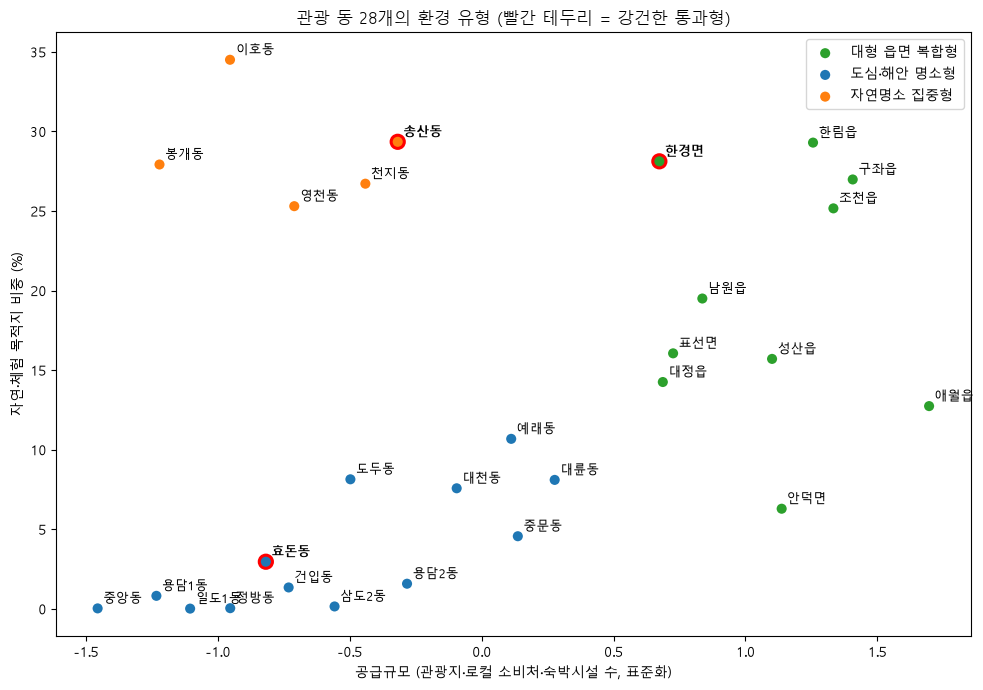

In [13]:
TYPE_COLORS = {'대형 읍면 복합형': 'tab:green', '자연명소 집중형': 'tab:orange', '도심·해안 명소형': 'tab:blue'}
fig, ax = plt.subplots(figsize=(10, 7))
for ty, g in T.groupby('유형'):
    ax.scatter(g['공급규모'], g['자연체험비중'] * 100, s=90, c=TYPE_COLORS[ty], label=ty,
               edgecolor=np.where(g.index.isin(PASS), 'red', 'white'), linewidth=2.2)
for n, r in T.iterrows():
    ax.annotate(n, (r['공급규모'], r['자연체험비중'] * 100), xytext=(4, 4), textcoords='offset points', fontsize=9,
                fontweight='bold' if n in PASS else 'normal')
ax.set_xlabel('공급규모 (관광지·로컬 소비처·숙박시설 수, 표준화)'); ax.set_ylabel('자연·체험 목적지 비중 (%)')
ax.set_title('관광 동 28개의 환경 유형 (빨간 테두리 = 강건한 통과형)'); ax.legend()
plt.tight_layout(); save(fig, '02_관광환경_유형.png'); plt.show()

## 6. 군집 내 타깃·벤치마킹 선정
- **타깃**: 강건한 통과형 동 (유형별로 하나씩 나오는지 확인)
- **벤치마킹**: 실제로 기대 이상 소비하고(합의점수 < 0) 관광지 도착 규모가 비슷한(1/3~3배) 동 중 환경(공급규모·자연체험비중)이 가장 가까운 동.
  같은 유형 안에서 먼저 찾고, 유형 전체가 기대 이하라 성공 사례가 없으면 다른 유형까지 넓혀 환경이 가장 가까운 동을 쓴다 (넓힌 경우 표시)

In [14]:
T['유형내_Z'] = T.groupby('유형')['합의점수'].transform(lambda x: (x - x.mean()) / x.std())
env_z = pd.DataFrame(StandardScaler().fit_transform(T[CLU_COLS]), index=T.index, columns=CLU_COLS)
pairs = []
for tgt in T.loc[PASS].sort_values('합의점수', ascending=False).index:
    ty = T.at[tgt, '유형']
    dist = np.sqrt(((env_z - env_z.loc[tgt]) ** 2).sum(axis=1)).drop(tgt)
    scale = T.loc[dist.index, '관광지_관광객도착'] / T.at[tgt, '관광지_관광객도착']
    good = (T.loc[dist.index, '합의점수'] < 0) & scale.between(1 / 3, 3)   # 기대 이상 소비 + 관광 수요 규모가 비슷(1/3~3배)
    same = good & (T.loc[dist.index, '유형'] == ty)
    pool = dist[same] if same.any() else dist[good]
    bm = pool.idxmin()                                                     # 조건을 만족하는 동 중 환경이 가장 비슷한 동
    pairs.append({'유형': ty, '타깃': tgt, '타깃_합의점수': T.at[tgt, '합의점수'], '벤치마킹': bm,
                  '벤치_유형': T.at[bm, '유형'], '벤치_합의점수': T.at[bm, '합의점수'],
                  '유형 밖 벤치마킹': not same.any(), '환경 가까운 성공 후보': ', '.join(pool.nsmallest(3).index)})
PAIRS = pd.DataFrame(pairs)
print(PAIRS.round(2).to_string(index=False))
TARGETS = PAIRS['타깃'].tolist()
BENCH = dict(zip(PAIRS['타깃'], PAIRS['벤치마킹']))

       유형  타깃  타깃_합의점수 벤치마킹     벤치_유형  벤치_합의점수  유형 밖 벤치마킹   환경 가까운 성공 후보
대형 읍면 복합형 한경면     1.13  조천읍 대형 읍면 복합형    -0.01      False            조천읍
 자연명소 집중형 송산동     0.93  대륜동 도심·해안 명소형    -0.84       True 대륜동, 중문동, 용담2동
도심·해안 명소형 효돈동     0.92 용담2동 도심·해안 명소형    -2.02      False 용담2동, 중문동, 대륜동


## 7. 타깃 심층 진단
### 7-1. 소비 퍼널 분해: "안 멈추나" vs "멈춰도 덜 쓰나"
관광지 도착 1건당 관광객 소비(숙박 제외)를 두 단계로 **정확히** 나눈다.

$$\frac{소비}{관광지\ 도착} = \underbrace{\frac{로컬\ 소비처\ 도착}{관광지\ 도착}}_{로컬전환비:\ 멈추는가} \times \underbrace{\frac{소비}{로컬\ 소비처\ 도착}}_{방문당\ 소비:\ 멈추면\ 쓰는가}$$

로그를 취하면 벤치마킹 대비 격차가 두 항의 합으로 나뉘어, 어느 단계에서 소비가 새는지 % 단위로 말할 수 있다.
- 로컬전환비가 원인 → 관광지에서 로컬 상권으로 **동선을 끌어오는** 처방 (연계 쿠폰, 동선 안내, 거점 쉼터)
- 방문당 소비가 원인 → 들른 곳에서 **객단가를 올리는** 처방 (특산 메뉴, 체험 결합 상품, 지역화폐 추가 적립)

In [15]:
T['도착당소비'] = T[SPEND] / T['관광지_관광객도착']
T['로컬방문당소비'] = T[SPEND] / T['로컬_관광객도착']
T['체류율'] = T['총방문'] / T['차량도착']        # SKT 30분+ 체류 방문 ÷ 티맵 차량 도착. 단위가 달라 수준이 아니라 동 간 상대 비교용
T['로컬공급비'] = T['로컬소비처수'] / T['관광지수'].replace(0, np.nan)
assert np.allclose(T['도착당소비'], T['로컬전환비'] * T['로컬방문당소비'])

FUN = ['관광지_관광객도착', '체류율', '로컬공급비', '로컬전환비', '로컬방문당소비', '도착당소비', '합의점수']
rows = []
for tgt in TARGETS:
    ty = T.at[tgt, '유형']
    bm = BENCH[tgt]
    med = T[T['유형'] == ty][FUN].median().rename(f'{ty} 중앙값')
    rows.append(pd.concat([T.loc[tgt, FUN].rename(f'★ {tgt}'), T.loc[bm, FUN].rename(f'벤치마킹 {bm}'), med], axis=1).T)
    for ref_name, ref in [(f'벤치마킹 {bm}', T.loc[bm]), (f'{ty} 중앙값', med)]:
        gap = np.log(T.at[tgt, '도착당소비'] / ref['도착당소비'])
        conv = np.log(T.at[tgt, '로컬전환비'] / ref['로컬전환비'])
        spend = np.log(T.at[tgt, '로컬방문당소비'] / ref['로컬방문당소비'])
        print(f'{tgt} vs {ref_name}: 도착당소비 {np.exp(gap) - 1:+.0%}'
              f' = 로컬전환비 요인 {np.exp(conv) - 1:+.0%} x 방문당소비 요인 {np.exp(spend) - 1:+.0%}'
              f' | 격차 기여: 안 멈춤 {conv / gap:.0%}, 덜 씀 {spend / gap:.0%}')
FUNNEL = pd.concat(rows)
print(); print(FUNNEL.to_string())

한경면 vs 벤치마킹 조천읍: 도착당소비 -36% = 로컬전환비 요인 -30% x 방문당소비 요인 -9% | 격차 기여: 안 멈춤 79%, 덜 씀 21%
한경면 vs 대형 읍면 복합형 중앙값: 도착당소비 -31% = 로컬전환비 요인 -31% x 방문당소비 요인 -5% | 격차 기여: 안 멈춤 102%, 덜 씀 13%
송산동 vs 벤치마킹 대륜동: 도착당소비 -78% = 로컬전환비 요인 -30% x 방문당소비 요인 -69% | 격차 기여: 안 멈춤 23%, 덜 씀 77%
송산동 vs 자연명소 집중형 중앙값: 도착당소비 -14% = 로컬전환비 요인 +32% x 방문당소비 요인 -42% | 격차 기여: 안 멈춤 -189%, 덜 씀 367%
효돈동 vs 벤치마킹 용담2동: 도착당소비 -97% = 로컬전환비 요인 -75% x 방문당소비 요인 -87% | 격차 기여: 안 멈춤 40%, 덜 씀 60%
효돈동 vs 도심·해안 명소형 중앙값: 도착당소비 -87% = 로컬전환비 요인 -66% x 방문당소비 요인 -35% | 격차 기여: 안 멈춤 54%, 덜 씀 21%

               관광지_관광객도착   체류율  로컬공급비  로컬전환비      로컬방문당소비         도착당소비  합의점수
★ 한경면         163,767.00 12.96   3.46   0.76   606,376.59    458,091.71  1.13
벤치마킹 조천읍      455,348.00  9.97   4.96   1.07   664,440.17    712,125.11 -0.01
대형 읍면 복합형 중앙값 437,698.50  9.81   5.04   1.10   635,408.38    661,373.17  0.18
★ 송산동          82,488.00 14.88   2.85   0.99   561,071.93    553,651.10  0.93
벤치마킹 대륜동       69,827.00  9.32   5.36   1.40 1,805,405.94  2,531,451.7

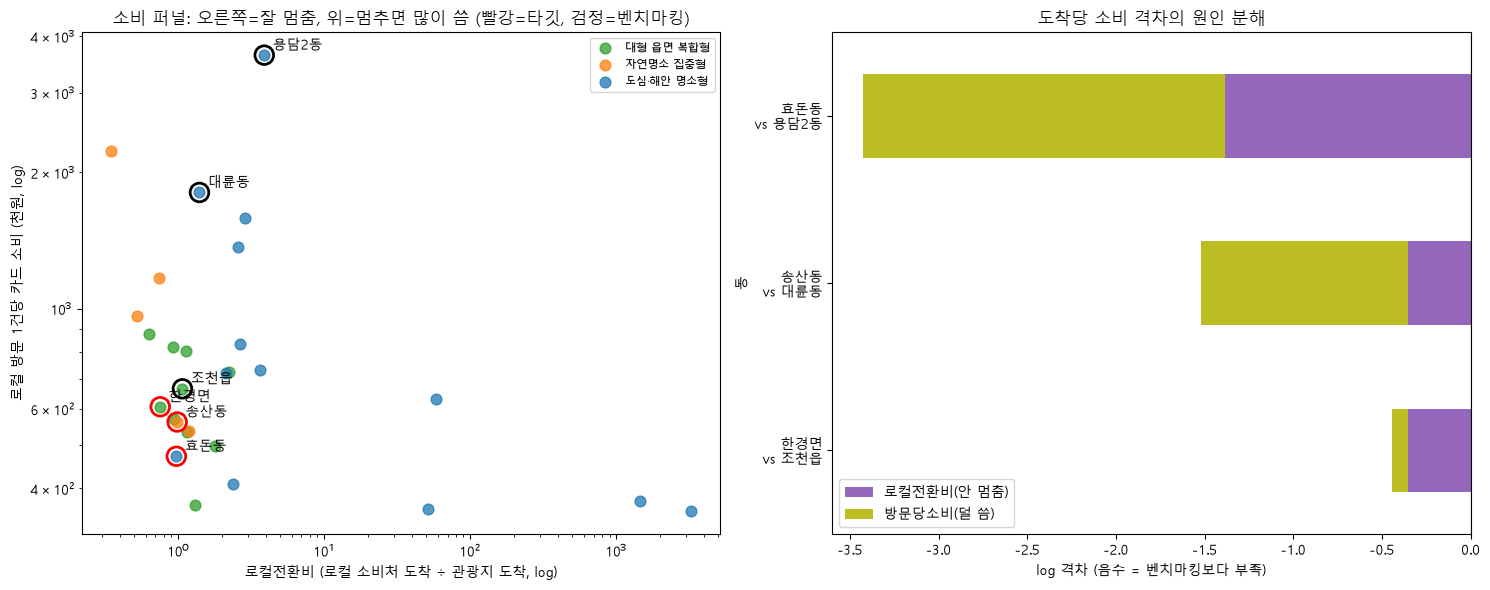

In [16]:
types_order = list(TYPE_COLORS)
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for ty in types_order:
    g = T[T['유형'] == ty]
    ax[0].scatter(g['로컬전환비'], g['로컬방문당소비'] / 1e3, c=TYPE_COLORS[ty], s=60, label=ty, alpha=0.75)
for n in TARGETS + list(BENCH.values()):
    r = T.loc[n]
    ax[0].scatter(r['로컬전환비'], r['로컬방문당소비'] / 1e3, s=180, facecolor='none',
                  edgecolor='red' if n in TARGETS else 'black', linewidth=2)
    ax[0].annotate(n, (r['로컬전환비'], r['로컬방문당소비'] / 1e3), xytext=(6, 4), textcoords='offset points', fontsize=10)
ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('로컬전환비 (로컬 소비처 도착 ÷ 관광지 도착, log)'); ax[0].set_ylabel('로컬 방문 1건당 카드 소비 (천원, log)')
ax[0].set_title('소비 퍼널: 오른쪽=잘 멈춤, 위=멈추면 많이 씀 (빨강=타깃, 검정=벤치마킹)'); ax[0].legend(fontsize=8)
dec = pd.DataFrame([{'동': f'{tgt}\nvs {BENCH[tgt]}',
                     '로컬전환비(안 멈춤)': np.log(T.at[tgt, '로컬전환비'] / T.at[BENCH[tgt], '로컬전환비']),
                     '방문당소비(덜 씀)': np.log(T.at[tgt, '로컬방문당소비'] / T.at[BENCH[tgt], '로컬방문당소비'])}
                    for tgt in TARGETS]).set_index('동')
dec.plot.barh(stacked=True, ax=ax[1], color=['tab:purple', 'tab:olive'])
ax[1].axvline(0, color='k', lw=0.8)
ax[1].set_xlabel('log 격차 (음수 = 벤치마킹보다 부족)'); ax[1].set_title('도착당 소비 격차의 원인 분해')
plt.tight_layout(); save(fig, '03_소비퍼널_분해.png'); plt.show()

### 7-2. 업종별: 어떤 업종에서 소비가 새나 (숙박 제외, 관광지 도착 1건당)

In [17]:
BIZ_NL = [b for b in BIZ if b != '숙박업']
per = biz[BIZ_NL].div(D['관광지_관광객도착'], axis=0)
for tgt in TARGETS:
    bm, ty = BENCH[tgt], T.at[tgt, '유형']
    tab = pd.DataFrame({tgt: per.loc[tgt], f'벤치 {bm}': per.loc[bm],
                        f'{ty} 중앙값': per.loc[T.index[T['유형'] == ty]].median()})
    tab['벤치 대비'] = tab[tgt] / tab[f'벤치 {bm}']
    tab['유형중앙 대비'] = tab[tgt] / tab[f'{ty} 중앙값']
    tab['격차(원/도착)'] = tab[f'{ty} 중앙값'] - tab[tgt]
    print(f'\n[{tgt}] 관광지 도착 1건당 업종별 카드 소비(원)'); print(tab.round(2).to_string())


[한경면] 관광지 도착 1건당 업종별 카드 소비(원)
                한경면     벤치 조천읍  대형 읍면 복합형 중앙값  벤치 대비  유형중앙 대비   격차(원/도착)
업종명                                                                     
기타서비스업     2,319.10   8,209.08       6,362.80   0.28     0.36   4,043.70
소매업      120,308.96 179,029.69     180,795.65   0.67     0.67  60,486.69
예술스포츠여가업 109,563.29 113,861.64      81,544.96   0.96     1.34 -28,018.33
음식점업     225,900.36 411,024.69     343,786.81   0.55     0.66 117,886.44

[송산동] 관광지 도착 1건당 업종별 카드 소비(원)
                송산동       벤치 대륜동  자연명소 집중형 중앙값  벤치 대비  유형중앙 대비    격차(원/도착)
업종명                                                                       
기타서비스업     5,341.67   567,620.61      5,341.67   0.01     1.00        0.00
소매업      107,142.23 1,261,942.30    362,357.04   0.08     0.30  255,214.81
예술스포츠여가업   2,285.80    43,960.05      6,565.35   0.05     0.35    4,279.55
음식점업     438,881.40   657,928.84    253,482.66   0.67     1.73 -185,398.74

[효돈동] 관광지 도착 1건당 업종별 카드 소비(원)
                효돈동

### 7-3. 핀포인트: 동 안에서 정확히 어디인가 (리·법정동 단위)
관광지 도착은 많은데 같은 마을 안 로컬 소비처 도착이 적은 곳 = 체류 요소를 넣을 지점
읍면은 '리', 동은 '법정동' 단위. 송산동 안의 '동홍동'처럼 행정동과 이름이 같은 법정동이 있으니 발표 때 "정방폭포 일대"처럼 장소로 부를 것

In [18]:
p['법정'] = p['목적지주소'].str.extract(r'(?:제주시|서귀포시)\s+(\S+)')[0]
p['리'] = p['목적지주소'].str.extract(r'(?:제주시|서귀포시)\s+\S+[읍면]\s+(\S+리)')[0]
p['핀단위'] = p['리'].fillna(p['법정'])

def pin_table(names):
    q = p[p['읍면동명'].isin(names)]
    t = q.pivot_table(index=['읍면동명', '핀단위'], columns='그룹', values='관광객도착', aggfunc='sum', fill_value=0)
    for g_ in ATTR_G + LOCAL_G:
        if g_ not in t:
            t[g_] = 0
    t['관광지도착'] = t[ATTR_G].sum(axis=1)
    t['로컬도착'] = t[LOCAL_G].sum(axis=1)
    t['로컬전환비'] = t['로컬도착'] / t['관광지도착'].replace(0, np.nan)
    t['로컬소비처수'] = q[q['그룹'].isin(LOCAL_G)].drop_duplicates(['목적지명', '목적지주소']).groupby(['읍면동명', '핀단위']).size()
    return t.fillna({'로컬소비처수': 0})

pin_all = pin_table(DONGS)
ref_pin = pin_all.loc[pin_all['관광지도착'] >= 5000, '로컬전환비'].median()

def top_spots(dong, pin, groups, k=3):
    q = p[(p['읍면동명'] == dong) & (p['핀단위'] == pin) & p['그룹'].isin(groups)]
    s_ = q.groupby('목적지명')['관광객도착'].sum().nlargest(k)
    return ', '.join(f'{n_}({v_ / 1e3:.0f}천)' for n_, v_ in s_.items())

PIN = pin_table(TARGETS + list(BENCH.values()))
PIN = PIN[PIN['관광지도착'] >= 5000].copy()
PIN['기준 대비 로컬 부족(도착 수)'] = (ref_pin * PIN['관광지도착'] - PIN['로컬도착']).clip(lower=0)
PIN['대표 관광지'] = [top_spots(d, n, ATTR_G) for d, n in PIN.index]
PIN['대표 로컬 소비처'] = [top_spots(d, n, LOCAL_G, 2) for d, n in PIN.index]
print(f'제주 전체 마을 단위 로컬전환비 중앙값(관광지 도착 5천 건 이상 마을): {ref_pin:.2f}')
cols = ['관광지도착', '로컬도착', '로컬전환비', '로컬소비처수', '기준 대비 로컬 부족(도착 수)', '대표 관광지', '대표 로컬 소비처']
for d in TARGETS + list(BENCH.values()):
    if d in PIN.index.get_level_values(0):
        print(f'\n[{d}]' + (' ★타깃' if d in TARGETS else ' (벤치마킹)'))
        print(PIN.loc[d].sort_values('관광지도착', ascending=False)[cols].round(2).to_string())
PIN.reset_index().to_csv(os.path.join(OUT_DIR, '핀포인트_마을단위.csv'), index=False, encoding='utf-8-sig')

제주 전체 마을 단위 로컬전환비 중앙값(관광지 도착 5천 건 이상 마을): 1.03

[한경면] ★타깃
그룹   관광지도착   로컬도착  로컬전환비  로컬소비처수  기준 대비 로컬 부족(도착 수)                                 대표 관광지                       대표 로컬 소비처
핀단위                                                                                                                       
신창리  65167   7175   0.11   47.00          59,821.84   신창풍차해안도로(48천), 싱계물공원(6천), 신창풍차해안(6천)     풍차로가는길(1천), 테이크타임커피로스터스(1천)
고산리  37154  15725   0.42   90.00          22,472.25      수월봉(8천), 수월봉지질트레일(7천), 수월봉전망대(6천)        금자매식당/[한식](4천), 한경가든(2천)
저지리  26392  30990   1.17  114.00               0.00  제주현대미술관(9천), 환상숲곶자왈공원(9천), 생각하는정원(3천)     뚱보아저씨/[한식](7천), 책방 소리소문(4천)
청수리  22917  10070   0.44   35.00          13,490.49       산양큰엉곶(19천), 스위트몽키(2천), 르벙쓸레브(1천)                양가형제(5천), 이립(1천)
판포리   6970  20818   2.99   28.00               0.00    힐링카약파크비체올린(5천), 비체올린(1천), 플레이판포(1천)  바다를본돼지/제주협재판포본점(6천), 울트라마린(5천)

[송산동] ★타깃
그룹   관광지도착   로컬도착  로컬전환비  로컬소비처수  기준 대비 로컬 부족(도착 수)                   

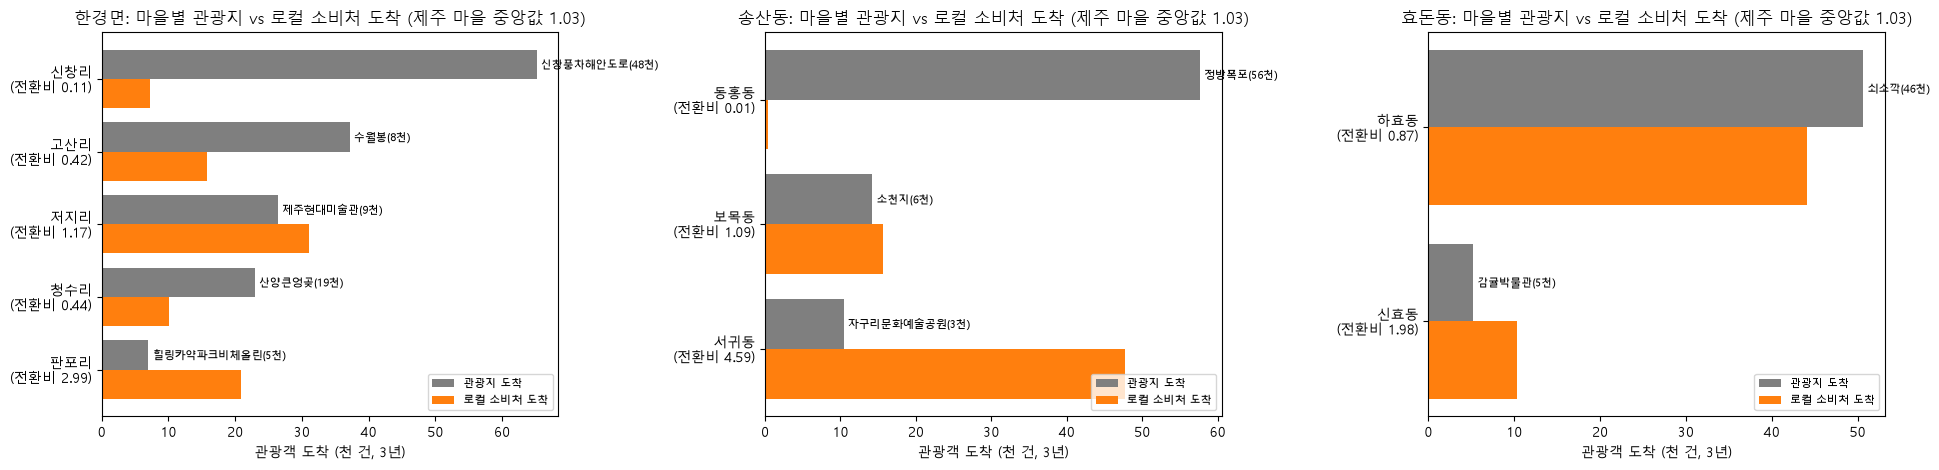

In [19]:
fig, ax = plt.subplots(1, len(TARGETS), figsize=(6.5 * len(TARGETS), 4.8), squeeze=False)
for i, tgt in enumerate(TARGETS):
    t_ = PIN.loc[tgt].sort_values('관광지도착')
    y = np.arange(len(t_))
    ax[0, i].barh(y + 0.2, t_['관광지도착'] / 1e3, height=0.4, color='tab:gray', label='관광지 도착')
    ax[0, i].barh(y - 0.2, t_['로컬도착'] / 1e3, height=0.4, color='tab:orange', label='로컬 소비처 도착')
    ax[0, i].set_yticks(y, [f'{n}\n(전환비 {r:.2f})' for n, r in zip(t_.index, t_['로컬전환비'])])
    for yy, (_, r) in zip(y, t_.iterrows()):
        ax[0, i].annotate(r['대표 관광지'].split(',')[0], (r['관광지도착'] / 1e3, yy + 0.2), xytext=(3, -3),
                          textcoords='offset points', fontsize=8)
    ax[0, i].set_xlabel('관광객 도착 (천 건, 3년)'); ax[0, i].legend(fontsize=8, loc='lower right')
    ax[0, i].set_title(f'{tgt}: 마을별 관광지 vs 로컬 소비처 도착 (제주 마을 중앙값 {ref_pin:.2f})')
plt.tight_layout(); save(fig, '05_핀포인트_마을.png'); plt.show()

### 7-4. 언제 새나: 월별 도착당 소비 (타깃 ÷ 벤치마킹)

한경면: 벤치마킹 대비 격차가 큰 달 [2, 3, 6] | 관광지 도착 많은 달 [6, 8, 5]
송산동: 벤치마킹 대비 격차가 큰 달 [6, 5, 7] | 관광지 도착 많은 달 [8, 5, 10]
효돈동: 벤치마킹 대비 격차가 큰 달 [9, 7, 8] | 관광지 도착 많은 달 [8, 5, 10]


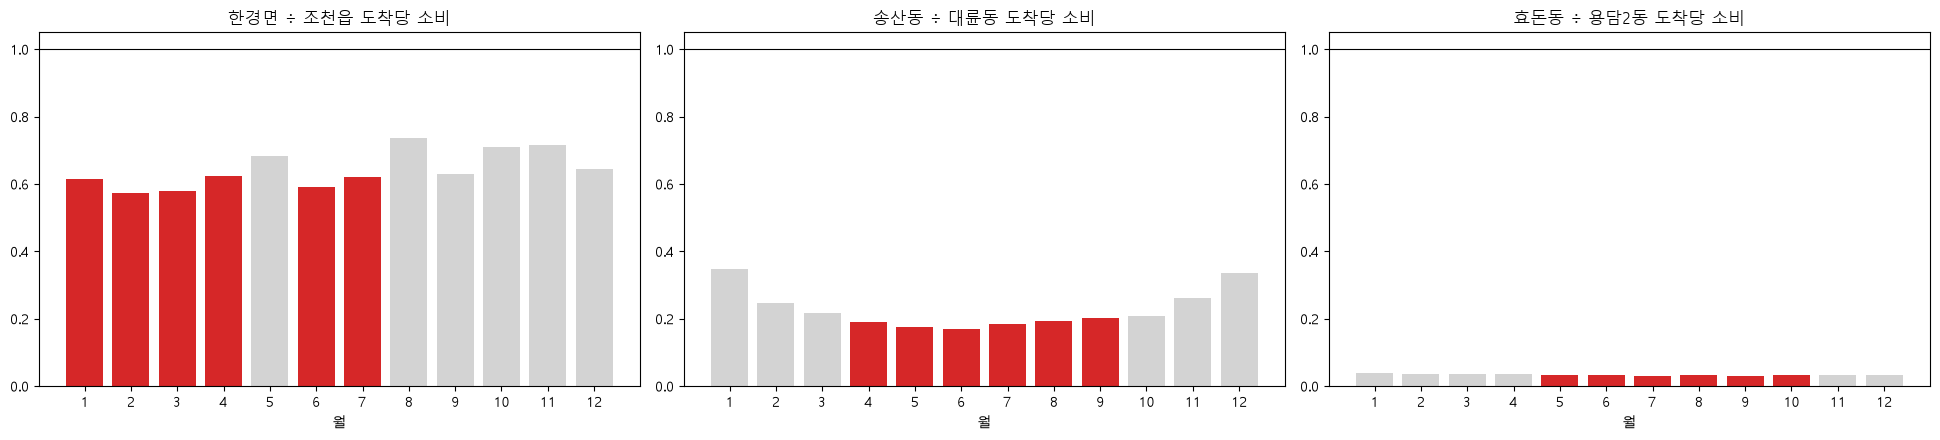

In [20]:
attr_m = p[p['그룹'].isin(ATTR_G)].groupby(['월', '읍면동명'])['관광객도착'].sum()
spend_m = st[st['업종명'] != '숙박업'].groupby(['월', '읍면동명'])['소비금액'].sum()
upa_m = (spend_m / attr_m).unstack()
season = upa_m.groupby(upa_m.index % 100).mean()
vol_m = attr_m.unstack()
fig, ax = plt.subplots(1, len(TARGETS), figsize=(6.5 * len(TARGETS), 4.5), squeeze=False)
for i, tgt in enumerate(TARGETS):
    bm = BENCH[tgt]
    ratio = season[tgt] / season[bm]
    ax[0, i].bar(ratio.index, ratio.values, color=np.where(ratio < ratio.median(), 'tab:red', 'lightgray'))
    ax[0, i].axhline(1, color='k', lw=0.8)
    ax[0, i].set_xticks(range(1, 13)); ax[0, i].set_xlabel('월')
    ax[0, i].set_title(f'{tgt} ÷ {bm} 도착당 소비')
    vol = vol_m[tgt].groupby(vol_m.index % 100).mean()
    print(f'{tgt}: 벤치마킹 대비 격차가 큰 달 {ratio.nsmallest(3).index.tolist()} | 관광지 도착 많은 달 {vol.nlargest(3).index.tolist()}')
plt.tight_layout(); save(fig, '04_월별_격차.png'); plt.show()

### 7-5. 레버 검증: 로컬 방문이 늘면 실제로 소비가 늘어나나
처방(로컬 상권으로 동선 연결)이 효과가 있으려면 "같은 동에서 로컬 소비처 방문이 늘어난 달에 카드 소비도 늘었는가"가 확인돼야 한다.
관광 동 28개 × 36개월 패널에서 **동 고정효과 + 월 고정효과**로 동마다 다른 고유 특성과 계절·전체 추세를 제거한 뒤

log 관광객 소비 = β₁ log 로컬 소비처 도착 + β₂ log 관광지 도착 + 동 효과 + 월 효과

를 추정한다 (표준오차는 동 단위 군집 강건). β₁이 양수면 "관광지 방문 규모가 같아도 로컬로 더 많이 들르면 소비가 는다"는 뜻.

In [21]:
loc_m_all = p[p['그룹'].isin(LOCAL_G)].groupby(['월', '읍면동명'])['관광객도착'].sum()
PN = pd.DataFrame({'spend': spend_m, 'local': loc_m_all, 'attr': attr_m}).reset_index()
PN = PN[PN['읍면동명'].isin(T.index)].dropna()
PN = PN[(PN[['spend', 'local', 'attr']] > 0).all(axis=1)]
for col_ in ['spend', 'local', 'attr']:
    PN[f'l_{col_}'] = np.log(PN[col_])

def twoway_demean(df, cols, n_iter=50):
    out = df[cols].copy()
    for _ in range(n_iter):                      # 불균형 패널 대비 반복 demean
        out = out - out.groupby(df['읍면동명']).transform('mean')
        out = out - out.groupby(df['월']).transform('mean')
    return out

W = twoway_demean(PN, ['l_spend', 'l_local', 'l_attr'])
X_ = W[['l_local', 'l_attr']].values; y_ = W['l_spend'].values
beta = np.linalg.lstsq(X_, y_, rcond=None)[0]
resid = y_ - X_ @ beta
XtX_inv = np.linalg.inv(X_.T @ X_)
meat = sum(np.outer(X_[g].T @ resid[g], X_[g].T @ resid[g])
           for g in [np.where(PN['읍면동명'].values == d)[0] for d in PN['읍면동명'].unique()])
G = PN['읍면동명'].nunique()
V = XtX_inv @ meat @ XtX_inv * G / (G - 1)
se = np.sqrt(np.diag(V))
LEVER = pd.DataFrame({'계수(탄력성)': beta, '군집강건 SE': se, 't': beta / se,
                      'p값': 2 * (1 - stats.t.cdf(np.abs(beta / se), G - 1))}, index=['log 로컬 소비처 도착', 'log 관광지 도착'])
print(f'패널: {PN["읍면동명"].nunique()}개 동 × {PN["월"].nunique()}개월 = {len(PN)}행')
print(LEVER.round(3).to_string())
print(f'\n→ 관광지 방문 규모가 같을 때 로컬 소비처 도착이 10% 늘면 관광객 카드 소비 약 {(1.1 ** beta[0] - 1) * 100:+.1f}%')

# 단면 분산 분해: 동 간 도착당 소비 차이 중 몇 %가 로컬전환비 차이에서 오나
lc, lv, lu = np.log(T['로컬전환비']), np.log(T['로컬방문당소비']), np.log(T['도착당소비'])
share_conv = np.cov(lc, lu)[0, 1] / lu.var()
print(f'관광 동 28개 사이 도착당 소비 차이(로그 분산) 중 로컬전환비 몫 {share_conv:.0%}, 방문당 소비 몫 {1 - share_conv:.0%}')

패널: 28개 동 × 36개월 = 994행
               계수(탄력성)  군집강건 SE    t   p값
log 로컬 소비처 도착     0.36     0.10 3.70 0.00
log 관광지 도착        0.02     0.03 0.64 0.53

→ 관광지 방문 규모가 같을 때 로컬 소비처 도착이 10% 늘면 관광객 카드 소비 약 +3.5%
관광 동 28개 사이 도착당 소비 차이(로그 분산) 중 로컬전환비 몫 104%, 방문당 소비 몫 -4%


## 8. 사후 검증: 2026년 상반기에도 그대로인가
2023~2025 데이터로 고른 타깃이 **분석에 쓰지 않은** 2026.01~06 데이터에서도 통과형으로 나오는지 확인한다.
인기장소 데이터는 2025.12까지라, 트래픽은 차량 도착·SKT 방문 2종 × 계산법 3종 = 6개 정의로 계산. 같은 상반기(1~6월)끼리 비교해 계절 차이를 없앤다.

In [22]:
def h1_consensus(c_, v_, s_):
    agg = pd.DataFrame({
        '차량도착': c_.groupby('읍면동명')['차량도착'].sum(),
        '총방문': v_.groupby('읍면동명')['총방문'].sum(),
        SPEND: s_[(s_['관광객구분'] != '도민') & (s_['업종명'] != '숙박업')].groupby('읍면동명')['소비금액'].sum(),
    }).loc[T.index]
    out = {}
    for tn, tc in {'차량': '차량도착', 'SKT방문': '총방문'}.items():
        for mn, sc in gap_scores(agg, tc, SPEND).items():
            out[f'{tn}_{mn}'] = sc
    sc = pd.DataFrame(out)
    return ((sc - sc.mean()) / sc.std()).mean(axis=1)

H1 = {}
for y in (2023, 2024, 2025):
    mk = lambda df: df[(df['월'] // 100 == y) & (df['월'] % 100 <= 6)]
    H1[f'{y}H1'] = h1_consensus(mk(c), mk(v), mk(s))
if os.path.exists(HOLD_DIR):
    c26, v26, s26 = load_core(HOLD_DIR)
    print(f'검증 데이터: {c26["월"].min()}~{c26["월"].max()} ({c26["월"].nunique()}개월)')
    H1['2026H1(검증)'] = h1_consensus(c26, v26, s26)
H1 = pd.DataFrame(H1)
H1_rank = H1.rank(ascending=False).astype(int)
show_rows = list(dict.fromkeys(TARGETS + list(BENCH.values()) + PASS))
print('\n상반기별 통과형 점수 순위 (관광 동 28개 중, 1위 = 가장 통과형):')
print(H1_rank.loc[show_rows].to_string())
print('\n2026 상반기와의 순위 상관(스피어만):')
print(H1.corr('spearman').round(2).iloc[:, -1].to_string())

검증 데이터: 202601~202606 (6개월)

상반기별 통과형 점수 순위 (관광 동 28개 중, 1위 = 가장 통과형):
      2023H1  2024H1  2025H1  2026H1(검증)
읍면동명                                    
한경면        2       1       1           2
송산동        4       3       6           6
효돈동        5       8      11          11
조천읍       15      16      15          14
대륜동       22      22      25          24
용담2동      28      27      27          25

2026 상반기와의 순위 상관(스피어만):
2023H1       0.61
2024H1       0.84
2025H1       0.95
2026H1(검증)   1.00


### 8-1. 최종 타깃 확정
강건한 통과형 3곳 중 2026 상반기 검증에서도 상위권을 유지한 **한경면·송산동**을 최종 타깃으로, 순위가 하락 추세인 **효돈동**은 3순위 모니터링 대상으로 둔다.
효돈동은 같은 유형(도심·해안 명소형)에 공항·도심 상권 동이 섞여 있어 벤치마킹 비교도 왜곡되기 쉽다.

In [23]:
FINAL = ['한경면', '송산동']
MONITOR = ['효돈동']
dec_tbl = pd.DataFrame({
    '유형': T.loc[PASS, '유형'], '합의점수': T.loc[PASS, '합의점수'], '민감도 선정(8개 중)': T.loc[PASS, '민감도_선정횟수'],
    '연도순위 23/24/25': T.loc[PASS, ['연도순위_2023', '연도순위_2024', '연도순위_2025']].astype(str).agg('/'.join, axis=1),
    '상반기순위 23/24/25': H1_rank.loc[PASS, ['2023H1', '2024H1', '2025H1']].astype(str).agg('/'.join, axis=1),
    '2026H1 검증순위': H1_rank.loc[PASS].iloc[:, -1],
})
dec_tbl['결정'] = ['최종 타깃' if n in FINAL else '3순위 모니터링' for n in dec_tbl.index]
print(dec_tbl.sort_values('2026H1 검증순위').to_string())

            유형  합의점수  민감도 선정(8개 중) 연도순위 23/24/25 상반기순위 23/24/25  2026H1 검증순위        결정
한경면  대형 읍면 복합형  1.13             8         3/1/1          2/1/1            2     최종 타깃
송산동   자연명소 집중형  0.93             5         2/3/6          4/3/6            6     최종 타깃
효돈동  도심·해안 명소형  0.92             7         4/2/5         5/8/11           11  3순위 모니터링


### 8-2. 지도로 보기 (피드백 2)
경계: 통계청 SGIS 행정동 경계(공공누리 제1유형)를 가공한 vuski/admdongkor ver20261001 (CC BY 4.0) 중 제주 43개 동. 파일은 `geo/jeju_emd.geojson`.
생활권 동(관광객비중 40% 미만)과 도서(추자·우도)는 통과형 판정 대상이 아니라 빗금으로 표시한다. 추자면은 본섬과 멀어 지도 범위에서 뺐다.

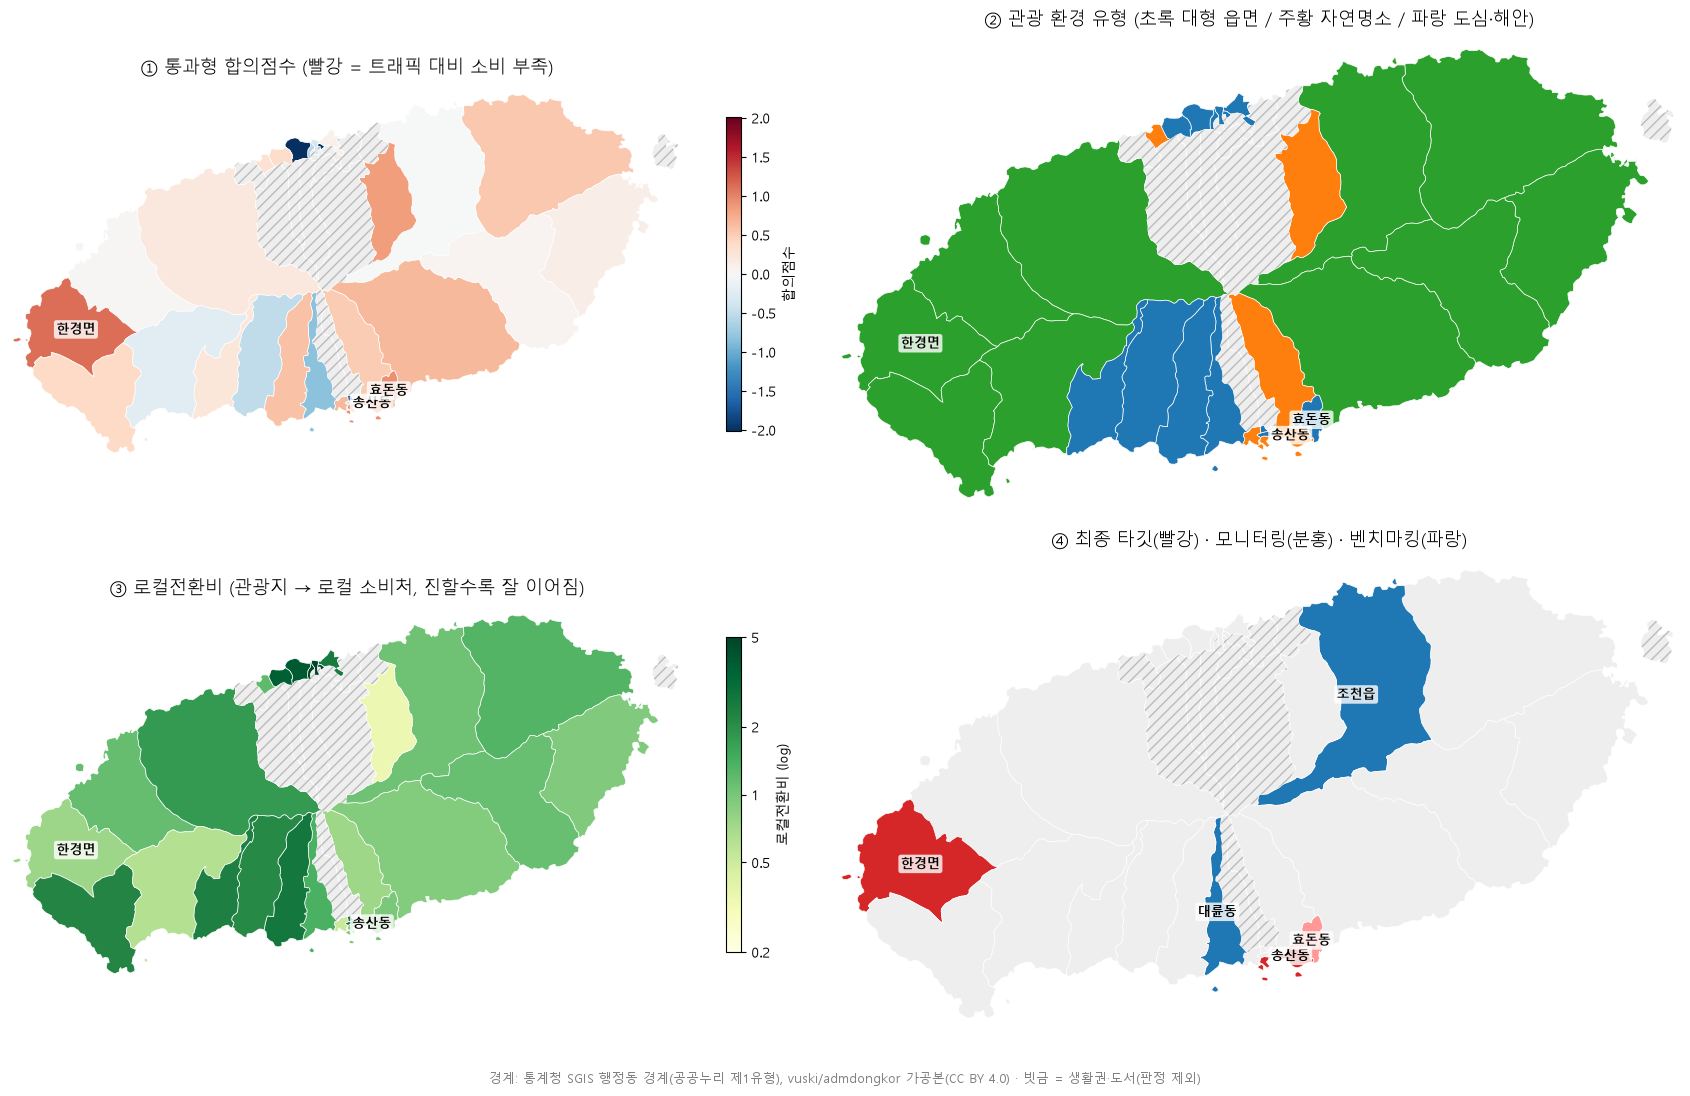

In [24]:
import json
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection
from matplotlib.colors import TwoSlopeNorm, LogNorm

GEO_PATH = os.environ.get('JEJU_GEO_PATH', os.path.join('geo', 'jeju_emd.geojson'))
GEO = json.load(open(GEO_PATH, encoding='utf-8'))
shapes = {}
for f_ in GEO['features']:
    nm = f_['properties']['adm_nm'].split()[-1]
    gm = f_['geometry']
    polys = gm['coordinates'] if gm['type'] == 'MultiPolygon' else [gm['coordinates']]
    shapes[nm] = [np.array(poly[0]) for poly in polys]
assert set(shapes) == set(DONGS), set(DONGS) ^ set(shapes)

def centroid(nm):
    big = max(shapes[nm], key=len)
    return big[:, 0].mean(), big[:, 1].mean()

def draw(ax, values=None, cmap='RdBu_r', norm=None, colors=None, title='', label_names=(), cbar_label='',
         extent=(126.14, 126.98, 33.18, 33.58), cbar_ticks=None, fs=9):
    patches, vals, facecols = [], [], []
    for nm, rings in shapes.items():
        for ring in rings:
            patches.append(MplPolygon(ring, closed=True))
            if colors is not None:
                facecols.append(colors.get(nm, '#eeeeee'))
            else:
                vals.append(values.get(nm, np.nan))
    pc = PatchCollection(patches, edgecolor='white', linewidth=0.5)
    if colors is not None:
        pc.set_facecolor(facecols)
    else:
        arr = np.ma.masked_invalid(np.array(vals, dtype=float))
        pc.set_array(arr); pc.set_cmap(cmap); pc.set_norm(norm)
        cm_ = plt.get_cmap(cmap).copy(); cm_.set_bad('#eeeeee'); pc.set_cmap(cm_)
        cb = plt.colorbar(pc, ax=ax, shrink=0.6, label=cbar_label)
        if cbar_ticks is not None:
            cb.set_ticks(cbar_ticks); cb.set_ticklabels([f'{x:g}' for x in cbar_ticks]); cb.minorticks_off()
    ax.add_collection(pc)
    excl = [n for n in DONGS if n not in T.index]
    hatch = PatchCollection([MplPolygon(r, closed=True) for n in excl for r in shapes[n]],
                            facecolor='none', edgecolor='#bbbbbb', hatch='///', linewidth=0)
    ax.add_collection(hatch)
    for nm in label_names:
        x, y = centroid(nm)
        ax.annotate(nm, (x, y), ha='center', va='center', fontsize=fs, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.8))
    ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
    ax.set_aspect(1 / np.cos(np.radians(33.4))); ax.axis('off'); ax.set_title(title, fontsize=13)

KEY = FINAL + MONITOR + [BENCH[n] for n in FINAL]
fig, ax = plt.subplots(2, 2, figsize=(17, 11))
lim = T['합의점수'].abs().max()
draw(ax[0, 0], T['합의점수'].to_dict(), 'RdBu_r', TwoSlopeNorm(0, -lim, lim),
     title='① 통과형 합의점수 (빨강 = 트래픽 대비 소비 부족)', label_names=PASS, cbar_label='합의점수')
draw(ax[0, 1], colors={n: TYPE_COLORS[t_] for n, t_ in T['유형'].items()},
     title='② 관광 환경 유형 (초록 대형 읍면 / 주황 자연명소 / 파랑 도심·해안)', label_names=PASS)
draw(ax[1, 0], T['로컬전환비'].clip(0.2, 5).to_dict(), 'YlGn', LogNorm(0.2, 5),
     title='③ 로컬전환비 (관광지 → 로컬 소비처, 진할수록 잘 이어짐)', label_names=FINAL, cbar_label='로컬전환비 (log)',
     cbar_ticks=[0.2, 0.5, 1, 2, 5])
role = {n: '#d62728' for n in FINAL} | {n: '#ff9896' for n in MONITOR} | {BENCH[n]: '#1f77b4' for n in FINAL}
draw(ax[1, 1], colors=role, title='④ 최종 타깃(빨강) · 모니터링(분홍) · 벤치마킹(파랑)', label_names=KEY)
fig.text(0.5, 0.01, '경계: 통계청 SGIS 행정동 경계(공공누리 제1유형), vuski/admdongkor 가공본(CC BY 4.0) · 빗금 = 생활권·도서(판정 제외)',
         ha='center', fontsize=9, color='gray')
plt.tight_layout(rect=(0, 0.02, 1, 1)); save(fig, '06_지도_통과형.png'); plt.show()

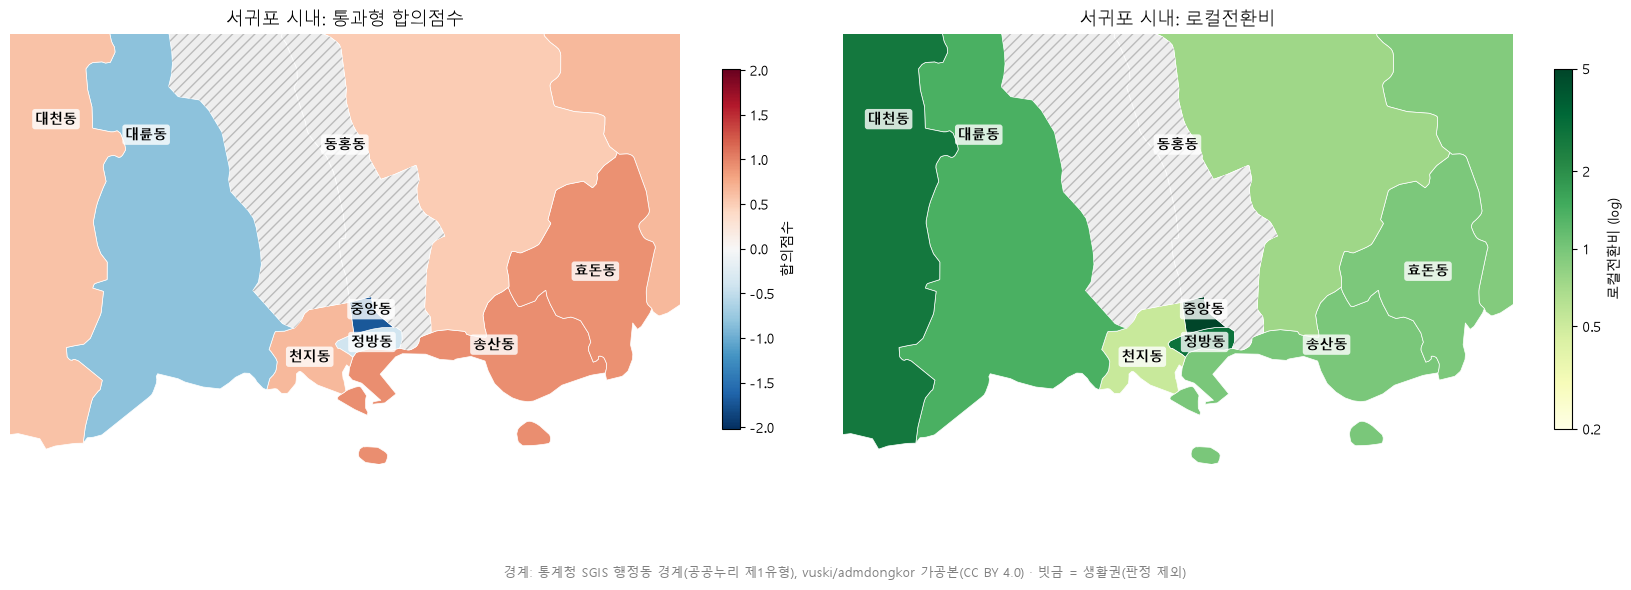

In [25]:
# 서귀포 시내 확대: 송산동·효돈동과 주변 동
SGP = (126.49, 126.63, 33.225, 33.30)
in_box = [n for n in DONGS if SGP[0] < centroid(n)[0] < SGP[1] and SGP[2] < centroid(n)[1] < SGP[3]]
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5))
draw(ax[0], T['합의점수'].to_dict(), 'RdBu_r', TwoSlopeNorm(0, -lim, lim), title='서귀포 시내: 통과형 합의점수',
     label_names=in_box, cbar_label='합의점수', extent=SGP, fs=10)
draw(ax[1], T['로컬전환비'].clip(0.2, 5).to_dict(), 'YlGn', LogNorm(0.2, 5), title='서귀포 시내: 로컬전환비',
     label_names=in_box, cbar_label='로컬전환비 (log)', extent=SGP, cbar_ticks=[0.2, 0.5, 1, 2, 5], fs=10)
fig.text(0.5, 0.01, '경계: 통계청 SGIS 행정동 경계(공공누리 제1유형), vuski/admdongkor 가공본(CC BY 4.0) · 빗금 = 생활권(판정 제외)',
         ha='center', fontsize=9, color='gray')
plt.tight_layout(rect=(0, 0.03, 1, 1)); save(fig, '07_지도_서귀포시내.png'); plt.show()

### 8-3. 스팟 단위: 어떤 관광지가 통과형이 되나, 같은 종류 중 잘 되는 곳은
동 단위 벤치마킹은 동 전체 상권 규모에 영향을 받는다. 그래서 **관광지(스팟) 하나가 마을 관광 수요의 절반 이상을 차지하는 마을**만 골라, 그 마을의 로컬전환비를 그 스팟의 전환비로 본다.
- 관광지 종류별로 묶어 어떤 종류가 구조적으로 통과형인지 본다
- 타깃 스팟과 **같은 종류**이면서 전환이 잘 되는 스팟을 스팟 벤치마킹으로 쓴다
- 마을 안 로컬 소비처 밀도(관광지 도착 1만 건당 소비처 수)로 **공급 부족 vs 연결 부족**을 나눈다
- 같은 기준으로 제주 전역의 통과형 스팟을 뽑아 **확대 적용 후보**로 제시한다

In [26]:
SPOT_TYPE = {
    '폭포·계곡': ['폭포/계곡'],
    '해안도로': ['드라이브코스'],
    '해변·포구': ['해수욕장', '포구', '섬', '등대'],
    '오름·숲·산': ['오름', '명산', '자연휴양림', '산림욕장', '공원', '도립공원', '국립공원', '동굴', '전망대', '캠프장'],
    '실내·테마(유료)': ['박물관/기념관', '미술관', '전시장', '화랑/전시관', '동식물원', '수족관', '테마파크', '관광단지', '공연장',
                   '종합위락시설', '온천'],
}
cat2spot = {c_: t_ for t_, cs in SPOT_TYPE.items() for c_ in cs}
SP = (p[p['그룹'].isin(ATTR_G)].groupby(['목적지명', '카테고리', '읍면동명', '핀단위'])['관광객도착'].sum().reset_index()
        .merge(pin_all[['관광지도착', '로컬도착', '로컬전환비', '로컬소비처수']].reset_index(), on=['읍면동명', '핀단위']))
SP['스팟종류'] = SP['카테고리'].map(cat2spot).fillna('기타 명소·체험')
SP['마을내_비중'] = SP['관광객도착'] / SP['관광지도착']
SP['로컬밀도'] = SP['로컬소비처수'] / (SP['관광지도착'] / 1e4)          # 관광지 도착 1만 건당 로컬 소비처 수
DOM = SP[(SP['관광객도착'] >= 10000) & (SP['마을내_비중'] >= 0.5)].sort_values('관광객도착', ascending=False).reset_index(drop=True)
CONV_MED, CONV_Q1 = DOM['로컬전환비'].median(), DOM['로컬전환비'].quantile(0.25)
DENS_MED = DOM['로컬밀도'].median()
print(f'마을을 지배하는 스팟 {len(DOM)}개 (관광객 도착 1만 건 이상, 마을 관광 수요의 50% 이상)')
print(f'스팟 로컬전환비 중앙값 {CONV_MED:.2f}, 하위 25% {CONV_Q1:.2f} | 로컬밀도 중앙값 {DENS_MED:.1f}곳/1만 건')
print('\n[스팟 종류별 로컬전환비]')
print(DOM.groupby('스팟종류')['로컬전환비'].agg(['count', 'median', 'min', 'max']).sort_values('median').round(2).to_string())

마을을 지배하는 스팟 45개 (관광객 도착 1만 건 이상, 마을 관광 수요의 50% 이상)
스팟 로컬전환비 중앙값 0.82, 하위 25% 0.40 | 로컬밀도 중앙값 21.0곳/1만 건

[스팟 종류별 로컬전환비]
           count  median  min   max
스팟종류                               
폭포·계곡          4    0.02 0.00  4.82
오름·숲·산         8    0.63 0.26  5.83
실내·테마(유료)      9    0.65 0.04  2.56
해변·포구          9    1.05 0.36 16.85
기타 명소·체험      12    1.15 0.01  2.87
해안도로           3    1.70 0.11  2.29


#### 타깃 스팟과 같은 종류 벤치마킹

In [27]:
TGT_SPOT = {}
for tgt in FINAL + MONITOR:
    TGT_SPOT[tgt] = DOM[DOM['읍면동명'] == tgt].sort_values('관광객도착', ascending=False).iloc[0]

def spot_bench(row, k=2):
    same = DOM[(DOM['스팟종류'] == row['스팟종류']) & (DOM['로컬전환비'] >= CONV_MED) & (DOM['목적지명'] != row['목적지명'])]
    if same.empty:                                              # 같은 종류에 성공 사례가 없으면 같은 시의 자연 관광지 중 규모가 비슷한 곳
        city = T.at[row['읍면동명'], '시']
        same = DOM[(DOM['로컬전환비'] >= CONV_MED) & (DOM['읍면동명'].map(D['시']) == city) &
                   (DOM['스팟종류'] != '실내·테마(유료)')]
        same = same.assign(비교='같은 시 자연 관광지(같은 종류 성공 사례 없음)')
    else:
        same = same.assign(비교='같은 종류')
    same = same.assign(규모차=np.abs(np.log(same['관광객도착'] / row['관광객도착'])))
    return same.nsmallest(k, '규모차')

sb_rows = []
for tgt, r in TGT_SPOT.items():
    for _, b in spot_bench(r).iterrows():
        sb_rows.append({'타깃': tgt, '타깃 스팟': r['목적지명'], '종류': r['스팟종류'],
                        '타깃 전환비': r['로컬전환비'], '타깃 로컬밀도': r['로컬밀도'],
                        '벤치 스팟': f"{b['목적지명']} ({b['읍면동명']} {b['핀단위']})", '비교 기준': b['비교'],
                        '벤치 전환비': b['로컬전환비'], '벤치 로컬밀도': b['로컬밀도'], '벤치 관광객도착': b['관광객도착']})
SPOT_BENCH = pd.DataFrame(sb_rows)
print(SPOT_BENCH.round(2).to_string(index=False))

 타깃    타깃 스팟       종류  타깃 전환비  타깃 로컬밀도                 벤치 스팟 비교 기준  벤치 전환비  벤치 로컬밀도  벤치 관광객도착
한경면 신창풍차해안도로     해안도로    0.11     7.21 도두동무지개해안도로 (도두동 도두일동) 같은 종류    2.29    37.51     36638
한경면 신창풍차해안도로     해안도로    0.11     7.21    하귀애월해안도로 (애월읍 구엄리) 같은 종류    1.70    21.04     29144
송산동     정방폭포    폭포·계곡    0.01     0.52       천지연폭포 (천지동 서귀동) 같은 종류    4.82   191.84     10338
효돈동      쇠소깍 기타 명소·체험    0.87    24.08       용두암 (용담2동 용담이동) 같은 종류    2.04    41.44     53405
효돈동      쇠소깍 기타 명소·체험    0.87    24.08       주상절리대 (중문동 중문동) 같은 종류    2.09    41.17     70664


#### 공급 부족 vs 연결 부족
- **공급 부족**: 전환비가 낮고 마을 안 로컬 소비처도 적다 → 소비처를 새로 만드는 처방 (팝업·푸드트럭·로드샵 거점)
- **연결 부족**: 소비처는 충분한데 전환비가 낮다 → 이미 있는 가게로 사람을 잇는 처방 (동선 안내, 연계 쿠폰, 셔틀·도보길)
- 인접 마을에 큰 상권이 있으면(예: 정방폭포 ↔ 서귀동) 공급 부족이어도 **인접 상권 연결**이 가장 빠른 처방

진단
전환 양호    23
공급 부족    18
연결 부족     4


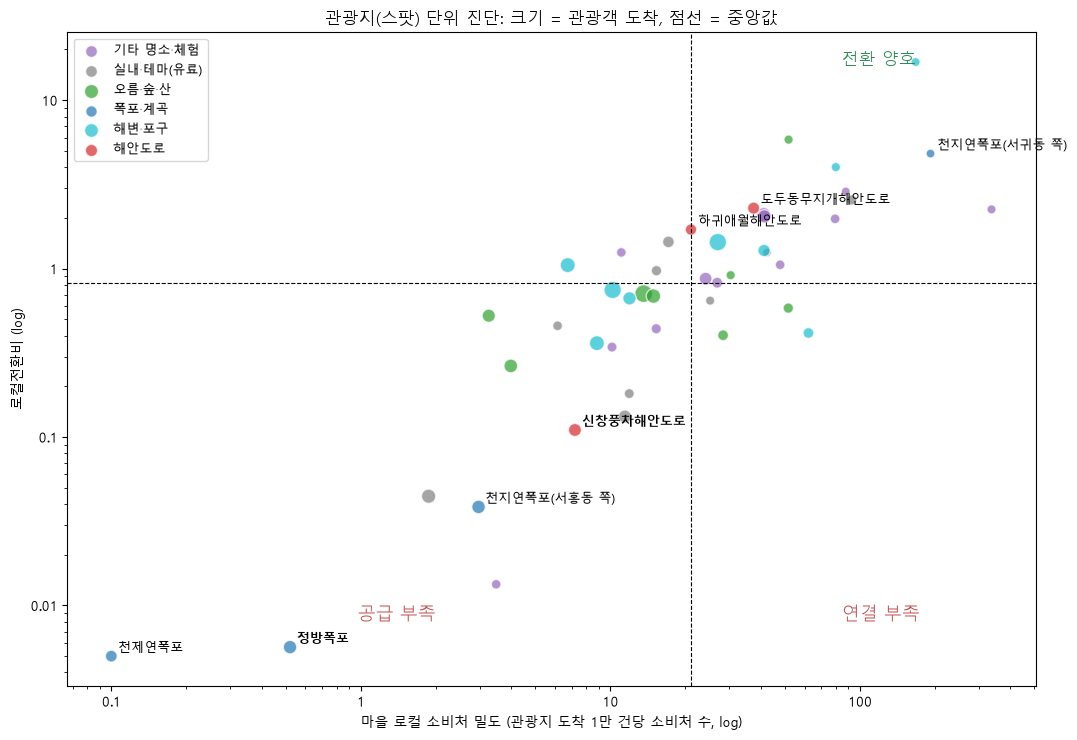

In [28]:
def diag(r):
    if r['로컬전환비'] >= CONV_MED:
        return '전환 양호'
    return '공급 부족' if r['로컬밀도'] < DENS_MED else '연결 부족'
DOM['진단'] = DOM.apply(diag, axis=1)
print(DOM['진단'].value_counts().to_string())

fig, ax = plt.subplots(figsize=(11, 7.5))
SPOT_COLORS = {'폭포·계곡': 'tab:blue', '해안도로': 'tab:red', '해변·포구': 'tab:cyan', '오름·숲·산': 'tab:green',
               '실내·테마(유료)': 'tab:gray', '기타 명소·체험': 'tab:purple'}
for ty_, g in DOM.groupby('스팟종류'):
    ax.scatter(g['로컬밀도'].clip(lower=0.1), g['로컬전환비'].clip(lower=0.005), s=np.sqrt(g['관광객도착']) / 2.5,
               c=SPOT_COLORS[ty_], alpha=0.7, label=ty_, edgecolor='white')
show_spots = set(TGT_SPOT[n]['목적지명'] for n in FINAL) | \
             set(SPOT_BENCH.loc[SPOT_BENCH['타깃'].isin(FINAL), '벤치 스팟'].str.split(' \\(').str[0]) | \
             set(DOM.loc[DOM['스팟종류'] == '폭포·계곡', '목적지명'])
for _, r in DOM[DOM['목적지명'].isin(show_spots)].iterrows():
    lbl_ = f"{r['목적지명']}({r['핀단위']} 쪽)" if (DOM['목적지명'] == r['목적지명']).sum() > 1 else r['목적지명']
    ax.annotate(lbl_, (max(r['로컬밀도'], 0.1), max(r['로컬전환비'], 0.005)), xytext=(5, 3), textcoords='offset points',
                fontsize=9, fontweight='bold' if r['목적지명'] in [v['목적지명'] for v in TGT_SPOT.values()] else 'normal')
ax.set_xscale('log'); ax.set_yscale('log')
from matplotlib.ticker import FuncFormatter
for axis_ in (ax.xaxis, ax.yaxis):
    axis_.set_major_formatter(FuncFormatter(lambda x_, _: f'{x_:g}'))
ax.axhline(CONV_MED, color='k', ls='--', lw=0.8); ax.axvline(DENS_MED, color='k', ls='--', lw=0.8)
ax.text(0.30, 0.10, '공급 부족', transform=ax.transAxes, fontsize=13, color='firebrick', alpha=0.8)
ax.text(0.80, 0.10, '연결 부족', transform=ax.transAxes, fontsize=13, color='firebrick', alpha=0.8)
ax.text(0.80, 0.95, '전환 양호', transform=ax.transAxes, fontsize=12, color='seagreen')
ax.set_xlabel('마을 로컬 소비처 밀도 (관광지 도착 1만 건당 소비처 수, log)'); ax.set_ylabel('로컬전환비 (log)')
ax.set_title('관광지(스팟) 단위 진단: 크기 = 관광객 도착, 점선 = 중앙값'); ax.legend(fontsize=9, loc='upper left')
plt.tight_layout(); save(fig, '08_스팟_공급연결진단.png'); plt.show()

#### 확대 적용: 제주 전역의 통과형 스팟
같은 기준(전환비 하위 25%, 관광객 도착 2만 건 이상)으로 제주 전역에서 다음 타깃 후보를 뽑는다. 실내·테마(유료) 스팟은 입장권·내부 매장에서 소비가 일어나 로컬전환비만으로 판단하기 어려워 따로 표시.

In [29]:
EXPAND = DOM[(DOM['로컬전환비'] <= CONV_Q1) & (DOM['관광객도착'] >= 20000)].copy()
EXPAND['비고'] = np.where(EXPAND['스팟종류'] == '실내·테마(유료)', '내부 소비형(해석 주의)',
                        np.where(EXPAND['읍면동명'].isin(FINAL), '최종 타깃', np.where(EXPAND['읍면동명'].isin(MONITOR), '모니터링', '확대 후보')))
cols_ = ['목적지명', '스팟종류', '읍면동명', '핀단위', '관광객도착', '로컬전환비', '로컬소비처수', '로컬밀도', '진단', '비고']
print(EXPAND[cols_].round(2).to_string(index=False))
falls = DOM[(DOM['스팟종류'] == '폭포·계곡') & (DOM['로컬전환비'] < CONV_Q1)]
print(f"\n통과형 폭포 {len(falls)}곳({', '.join(falls['목적지명'])}) 관광객 도착 합 {falls['관광객도착'].sum() / 1e3:,.0f}천 건,"
      f" 로컬전환비 {falls['로컬전환비'].round(2).tolist()} → 송산동 처방을 폭포형 스팟 공통 모델로 확대 가능")
print('같은 천지연폭포라도 서귀동 쪽 진입부(칠십리·서귀포항 상권 인접)는 로컬전환비',
      f"{DOM.loc[(DOM['목적지명'] == '천지연폭포') & (DOM['핀단위'] == '서귀동'), '로컬전환비'].round(2).tolist()} → 상권과 이어지면 전환된다는 근거")

     목적지명      스팟종류 읍면동명 핀단위  관광객도착  로컬전환비  로컬소비처수  로컬밀도    진단            비고
   곽지해수욕장     해변·포구  애월읍 곽지리  84624   0.36   95.00  8.83 공급 부족         확대 후보
아르떼뮤지엄/제주 실내·테마(유료)  애월읍 어음리  69685   0.04   24.00  1.87 공급 부족 내부 소비형(해석 주의)
      금오름    오름·숲·산  한림읍 금악리  59383   0.26   46.00  3.99 공급 부족         확대 후보
    천지연폭포     폭포·계곡  천지동 서홍동  56539   0.04   28.00  2.96 공급 부족         확대 후보
     정방폭포     폭포·계곡  송산동 동홍동  55544   0.01    3.00  0.52 공급 부족         최종 타깃
 신창풍차해안도로      해안도로  한경면 신창리  48389   0.11   47.00  7.21 공급 부족         최종 타깃
 에코랜드테마파크 실내·테마(유료)  조천읍 대흘리  47552   0.13   55.00 11.44 공급 부족 내부 소비형(해석 주의)
    천제연폭포     폭포·계곡  예래동 중문동  33189   0.00    0.00  0.00 공급 부족         확대 후보
제주절물자연휴양림    오름·숲·산  봉개동 봉개동  22962   0.40   97.00 28.30 연결 부족         확대 후보

통과형 폭포 3곳(천지연폭포, 정방폭포, 천제연폭포) 관광객 도착 합 145천 건, 로컬전환비 [0.04, 0.01, 0.0] → 송산동 처방을 폭포형 스팟 공통 모델로 확대 가능
같은 천지연폭포라도 서귀동 쪽 진입부(칠십리·서귀포항 상권 인접)는 로컬전환비 [4.82] → 상권과 이어지면 전환된다는 근거


#### 인접 상권 찾기
인기장소 데이터에는 좌표가 없어서, 전국주차장정보표준데이터의 주차장 위경도를 마을(리·법정동)별로 평균 내 마을 대표 위치로 쓴다.
스팟 마을에서 **2km 이내**이면서 전환이 잘 되고(제주 마을 중앙값 이상) 로컬 소비처가 50곳 이상인 마을을 "이어 줄 상권"으로 본다. 주차장이 없는 마을은 위치를 알 수 없어 제외된다.

In [30]:
pk = read(os.path.join(DATA_DIR, '전국주차장정보표준데이터.csv'), low_memory=False)
pk_addr = pk['소재지지번주소'].fillna('')
pk = pk[pk_addr.str.contains('제주특별자치도')].copy()
pk['핀단위'] = (pk['소재지지번주소'].str.extract(r'(?:제주시|서귀포시)\s+\S+[읍면]\s+(\S+리)')[0]
                .fillna(pk['소재지지번주소'].str.extract(r'(?:제주시|서귀포시)\s+(\S+)')[0]))
pk = pk[pk['위도'].between(33, 34) & pk['경도'].between(126, 127.1)]
PIN_XY = pk.groupby('핀단위')[['위도', '경도']].mean()
hub_tbl = pin_all.reset_index().groupby('핀단위')[['관광지도착', '로컬도착', '로컬소비처수']].sum()
hub_tbl['로컬전환비'] = hub_tbl['로컬도착'] / hub_tbl['관광지도착'].replace(0, np.nan)
print(f'위치를 잡은 마을 {len(PIN_XY)}개 (주차장 {len(pk)}곳 기준)')

def nearby_hubs(pin, max_km=2.0):
    if pin not in PIN_XY.index:
        return pd.DataFrame(columns=['거리km', '로컬전환비', '로컬소비처수'])
    la, lo = np.radians(PIN_XY.loc[pin])
    la2, lo2 = np.radians(PIN_XY['위도']), np.radians(PIN_XY['경도'])
    dist = 6371 * np.arccos(np.clip(np.sin(la) * np.sin(la2) + np.cos(la) * np.cos(la2) * np.cos(lo2 - lo), -1, 1))
    cand = hub_tbl.reindex(PIN_XY.index).assign(거리km=dist).drop(index=pin)
    return cand[(cand['거리km'] <= max_km) & (cand['로컬전환비'] >= ref_pin) & (cand['로컬소비처수'] >= 50)].sort_values('거리km')

# 확대 적용 효과: 후보 스팟의 로컬전환비가 스팟 중앙값까지 오르면 (방문당 소비는 소속 동 수준 유지, 3년 평균을 연 단위로)
EXP_NT = EXPAND[EXPAND['스팟종류'] != '실내·테마(유료)'].copy()
EXP_NT['연 추가 로컬방문'] = (CONV_MED - EXP_NT['로컬전환비']).clip(lower=0) * EXP_NT['관광지도착'] / 3
# 보수적 추정: 7-5 패널 탄력성 β를 써서 "동 전체 로컬 방문이 x% 늘 때 동 소비가 (1+x)^β - 1 늘어난다"
# 상한: 늘어난 로컬 방문이 그 동의 방문당 소비만큼 그대로 쓴다고 가정 (탄력성 1)
BETA = LEVER.iloc[0, 0]
dong_local_y = EXP_NT['읍면동명'].map(T['로컬_관광객도착']) / 3
dong_spend_y = EXP_NT['읍면동명'].map(T[SPEND]) / 3
EXP_NT['연 추가 소비_보수(억원)'] = dong_spend_y * ((1 + EXP_NT['연 추가 로컬방문'] / dong_local_y) ** BETA - 1) / 1e8
EXP_NT['연 추가 소비_상한(억원)'] = EXP_NT['연 추가 로컬방문'] * EXP_NT['읍면동명'].map(T['로컬방문당소비']) / 1e8
print('\n[확대 적용 효과: 로컬전환비 → 스팟 중앙값', f'{CONV_MED:.2f}, 탄력성 β={BETA:.2f}]')
print(EXP_NT[['목적지명', '읍면동명', '로컬전환비', '연 추가 로컬방문', '연 추가 소비_보수(억원)', '연 추가 소비_상한(억원)', '비고']]
      .round({'로컬전환비': 2, '연 추가 로컬방문': 0, '연 추가 소비_보수(억원)': 1, '연 추가 소비_상한(억원)': 1}).to_string(index=False))
for lab_, m_ in [('전체', slice(None)), ('최종 타깃 외 확대 후보', EXP_NT['비고'] == '확대 후보')]:
    sub_ = EXP_NT.loc[m_]
    print(f"{lab_}: 연 {sub_['연 추가 소비_보수(억원)'].sum():.0f}억 ~ {sub_['연 추가 소비_상한(억원)'].sum():.0f}억 원 (카드 결제 기준)")

DOM['인접 상권(2km)'] = [', '.join(f'{n}({r_["거리km"]:.1f}km)' for n, r_ in nearby_hubs(pn).iterrows()) for pn in DOM['핀단위']]
print(DOM.loc[DOM['로컬전환비'] < CONV_MED, ['목적지명', '핀단위', '로컬전환비', '진단', '인접 상권(2km)']].head(15).to_string(index=False))
DOM.to_csv(os.path.join(OUT_DIR, 'v5_스팟_진단.csv'), index=False, encoding='utf-8-sig')
SPOT_BENCH.to_csv(os.path.join(OUT_DIR, 'v5_스팟_벤치마킹.csv'), index=False, encoding='utf-8-sig')

위치를 잡은 마을 105개 (주차장 1053곳 기준)

[확대 적용 효과: 로컬전환비 → 스팟 중앙값 0.82, 탄력성 β=0.36]
     목적지명 읍면동명  로컬전환비  연 추가 로컬방문  연 추가 소비_보수(억원)  연 추가 소비_상한(억원)    비고
   곽지해수욕장  애월읍   0.36  16,631.00           29.10           82.40 확대 후보
      금오름  한림읍   0.26  21,525.00           39.60          114.90 확대 후보
    천지연폭포  천지동   0.04  24,758.00           63.70          238.90 확대 후보
     정방폭포  송산동   0.01  15,734.00           27.20           88.30 최종 타깃
 신창풍차해안도로  한경면   0.11  15,518.00           30.40           94.10 최종 타깃
    천제연폭포  예래동   0.00  12,100.00           17.40           49.50 확대 후보
제주절물자연휴양림  봉개동   0.40   4,828.00           30.70          107.60 확대 후보
전체: 연 238억 ~ 776억 원 (카드 결제 기준)
최종 타깃 외 확대 후보: 연 180억 ~ 593억 원 (카드 결제 기준)
     목적지명  핀단위  로컬전환비    진단                            인접 상권(2km)
    성산일출봉  성산리   0.71 공급 부족                                      
   협재해수욕장  협재리   0.75 공급 부족                            옹포리(1.5km)
   곽지해수욕장  곽지리   0.36 공급 부족                                      
      비자림  평대리   0.6

## 9. 기대 효과 시나리오 (2025년 카드 결제 기준)
두 가지 방식으로 계산해 범위로 제시한다. 카드 데이터 표본 기준 금액이라 실제 지역 매출보다 작을 수 있어 "카드 결제 기준"으로 표기한다.
- **A. 기대 소비 대비 격차**: 2025년 관광 동 28개에서 트래픽(3종)으로 예측한 기대 소비와 실제 소비의 차이 중 25/50/100%를 메우는 경우
- **B. 퍼널 레버**: 방문당 소비는 그대로 두고 **로컬전환비만** 같은 유형 중앙값(또는 벤치마킹)으로 끌어올리는 경우 → 동선 처방만의 효과

In [31]:
p25 = p[p['월'] // 100 == 2025]
st25 = st[(st['월'] // 100 == 2025) & (st['업종명'] != '숙박업')]
Y25 = pd.DataFrame({
    '차량도착': c[c['월'] // 100 == 2025].groupby('읍면동명')['차량도착'].sum(),
    '총방문': v[v['월'] // 100 == 2025].groupby('읍면동명')['총방문'].sum(),
    '관광지_관광객도착': p25[p25['그룹'].isin(ATTR_G)].groupby('읍면동명')['관광객도착'].sum(),
    '로컬_관광객도착': p25[p25['그룹'].isin(LOCAL_G)].groupby('읍면동명')['관광객도착'].sum(),
    SPEND: st25.groupby('읍면동명')['소비금액'].sum(),
}).loc[T.index]
logpred = []
for tc in TRAFFIC.values():
    b, a = np.polyfit(np.log(Y25[tc]), np.log(Y25[SPEND]), 1)
    logpred.append(a + b * np.log(Y25[tc]))
Y25['기대소비'] = np.exp(np.mean(logpred, axis=0))
Y25['로컬전환비'] = Y25['로컬_관광객도착'] / Y25['관광지_관광객도착']
Y25['방문당소비'] = Y25[SPEND] / Y25['로컬_관광객도착']

sc_rows = []
for tgt in FINAL + MONITOR:
    r = Y25.loc[tgt]
    gap = max(r['기대소비'] - r[SPEND], 0)
    for close in (0.25, 0.5, 1.0):
        sc_rows.append({'타깃': tgt, '방식': 'A. 기대 소비 대비 격차', '조건': f'격차 {close:.0%} 해소',
                        '추가 소비(억원/년)': gap * close / 1e8, '증가율': gap * close / r[SPEND]})
    if tgt in MONITOR:
        continue                                   # 모니터링 동은 벤치마킹 왜곡이 있어 A 방식만
    ty, bm = T.at[tgt, '유형'], BENCH[tgt]
    for ref_name, ref_conv in [(f'{ty} 중앙값', Y25.loc[T.index[T['유형'] == ty], '로컬전환비'].median()),
                               (f'벤치마킹 {bm}', Y25.at[bm, '로컬전환비'])]:
        add = max(ref_conv - r['로컬전환비'], 0) * r['관광지_관광객도착'] * r['방문당소비']
        sc_rows.append({'타깃': tgt, '방식': 'B. 로컬전환비 레버', '조건': f'{r["로컬전환비"]:.2f} → {ref_conv:.2f} ({ref_name})',
                        '추가 소비(억원/년)': add / 1e8, '증가율': add / r[SPEND]})
SCEN = pd.DataFrame(sc_rows)
print('2025 실제 관광객 카드 소비(숙박 제외, 억원):', (Y25.loc[FINAL + MONITOR, SPEND] / 1e8).round(1).to_dict())
print(SCEN.round(2).to_string(index=False))

2025 실제 관광객 카드 소비(숙박 제외, 억원): {'한경면': 252.0, '송산동': 149.3, '효돈동': 79.8}
 타깃             방식                          조건  추가 소비(억원/년)  증가율
한경면 A. 기대 소비 대비 격차                   격차 25% 해소        36.58 0.15
한경면 A. 기대 소비 대비 격차                   격차 50% 해소        73.16 0.29
한경면 A. 기대 소비 대비 격차                  격차 100% 해소       146.31 0.58
한경면    B. 로컬전환비 레버 0.81 → 1.15 (대형 읍면 복합형 중앙값)       103.82 0.41
한경면    B. 로컬전환비 레버      0.81 → 1.07 (벤치마킹 조천읍)        78.47 0.31
송산동 A. 기대 소비 대비 격차                   격차 25% 해소        26.01 0.17
송산동 A. 기대 소비 대비 격차                   격차 50% 해소        52.02 0.35
송산동 A. 기대 소비 대비 격차                  격차 100% 해소       104.04 0.70
송산동    B. 로컬전환비 레버  0.94 → 0.94 (자연명소 집중형 중앙값)         0.00 0.00
송산동    B. 로컬전환비 레버      0.94 → 1.20 (벤치마킹 대륜동)        40.31 0.27
효돈동 A. 기대 소비 대비 격차                   격차 25% 해소        20.27 0.25
효돈동 A. 기대 소비 대비 격차                   격차 50% 해소        40.53 0.51
효돈동 A. 기대 소비 대비 격차                  격차 100% 해소        81.06 1.02


## 10. 타깃별 액션 플랜과 KPI
앞 분석 결과를 타깃마다 한 장으로 모은다. 처방 문구는 진단 결과(어느 단계·업종·시기·마을)에 연결된 것만 남겼고, KPI는 이 노트북의 지표로 매월 다시 계산할 수 있는 값으로 정했다.

In [32]:
ACT_BY_BIZ = {
    '음식점업': '로컬 식당 연계 (관광지 출구·주차장에서 도보권 식당 쿠폰, 지역 식재료 대표 메뉴)',
    '소매업': '특산물·기념품 로드샵 팝업 (주차장·입구 동선 위)',
    '기타서비스업': '체류형 서비스 연계 (짐 보관·자전거·사진 등 관광지 주변 편의 서비스)',
    '예술스포츠여가업': '유료 체험·가이드 프로그램 결합 (예약형)',
}
pin_q25 = pin_all.loc[pin_all['관광지도착'] >= 5000, '로컬전환비'].quantile(0.25)
plans = []
for tgt in FINAL:
    bm, ty = BENCH[tgt], T.at[tgt, '유형']
    gap = np.log(T.at[tgt, '도착당소비'] / T.at[bm, '도착당소비'])
    conv_share = np.log(T.at[tgt, '로컬전환비'] / T.at[bm, '로컬전환비']) / gap
    pins = PIN.loc[tgt].sort_values('기준 대비 로컬 부족(도착 수)', ascending=False)
    pin = pins.index[0]
    leak = (per.loc[T.index[T['유형'] == ty]].median() - per.loc[tgt]).sort_values(ascending=False)
    leak = [b for b in leak.index if leak[b] > 0][:2]
    ratio = season[tgt] / season[bm]
    worst = sorted(ratio.nsmallest(3).index.tolist())
    sc_a = SCEN[(SCEN['타깃'] == tgt) & SCEN['방식'].str.startswith('A')]['추가 소비(억원/년)']
    conv_now = Y25.at[tgt, '로컬전환비']
    conv_goal = Y25.at[bm, '로컬전환비'] if Y25.at[bm, '로컬전환비'] > conv_now else Y25.loc[T.index[T['유형'] == ty], '로컬전환비'].median()
    main_issue = '안 멈춤(로컬로 이어지지 않음)' if conv_share >= 0.5 else '덜 씀(들러도 객단가 낮음)'
    pin_conv = PIN.at[(tgt, pin), '로컬전환비']
    spot = PIN.at[(tgt, pin), '대표 관광지'].split(',')[0].split('(')[0]
    pin_lbl = f'{pin}(법정동, {spot} 일대)' if pin in DONGS else pin   # 같은 이름의 행정동과 구분
    pin_pct = (pin_all.loc[pin_all['관광지도착'] >= 5000, '로컬전환비'] < pin_conv).mean()
    upa_now = Y25.at[tgt, SPEND] / Y25.at[tgt, '관광지_관광객도착']
    upa_goal = (Y25.at[tgt, SPEND] + 0.5 * max(Y25.at[tgt, '기대소비'] - Y25.at[tgt, SPEND], 0)) / Y25.at[tgt, '관광지_관광객도착']
    ts = TGT_SPOT[tgt]
    sbm = SPOT_BENCH[SPOT_BENCH['타깃'] == tgt]
    near_ok = nearby_hubs(ts['핀단위'])
    diag_ = DOM.loc[DOM['목적지명'] == ts['목적지명'], '진단'].iloc[0]
    if diag_ == '공급 부족':
        first = (f'[{ts["목적지명"]}] 로컬 소비 거점 신설 — 팝업·푸드트럭·로드샵 (마을 로컬 소비처 밀도 {ts["로컬밀도"]:.1f}곳/1만 건,'
                 f' 스팟 중앙값 {DENS_MED:.0f}곳)')
    else:
        first = f'[{ts["목적지명"]}] 이미 있는 마을 소비처로 잇는 동선 안내·연계 쿠폰 (로컬전환비 {ts["로컬전환비"]:.2f})'
    actions = [first]
    if len(near_ok):
        actions.append('인접 상권과 동선 연결: ' + ', '.join(f'{n}({r_["거리km"]:.1f}km, 로컬전환비 {r_["로컬전환비"]:.2f}, 소비처 {r_["로컬소비처수"]:.0f}곳)'
                                                for n, r_ in near_ok.iterrows()))
    actions += [ACT_BY_BIZ[b] for b in leak if b in ACT_BY_BIZ]
    actions.append(f'{", ".join(f"{m}월" for m in worst)} 집중 운영 (벤치마킹 대비 격차가 가장 큰 달)')
    plans.append({
        '타깃': tgt, '유형': ty, '벤치마킹': bm,
        '핵심 문제': f'{main_issue} — 벤치마킹 대비 격차의 {conv_share:.0%}가 로컬전환비'
                 f' / 단, 핀포인트 마을 {pin_lbl}의 로컬전환비는 {pin_conv:.2f}로 제주 마을 하위 {pin_pct:.0%}',
        '핀포인트 마을': f'{pin_lbl} (로컬 부족 {pins.iloc[0]["기준 대비 로컬 부족(도착 수)"] / 1e3:.0f}천 건)',
        '핵심 스팟·진단': f'{ts["목적지명"]} ({ts["스팟종류"]}) — {diag_}',
        '스팟 벤치마킹(같은 종류)': ' / '.join(f'{r_["벤치 스팟"]} 전환비 {r_["벤치 전환비"]:.2f}' for _, r_ in sbm.iterrows()),
        '새는 업종': ', '.join(leak),
        '취약 시기': ', '.join(f'{m}월' for m in worst),
        '제안 액션': ' / '.join(actions),
        'KPI ① 로컬전환비(2025)': f'{conv_now:.2f} → {conv_goal:.2f}',
        'KPI ② 관광지 도착당 소비(2025, 천원)': f'{upa_now / 1e3:,.0f} → {upa_goal / 1e3:,.0f} (기대 소비 격차 50% 해소)',
        'KPI ③ 핀포인트 마을 로컬전환비': f'{pin_lbl} {pin_conv:.2f} → {pin_q25:.2f} 이상 (제주 마을 하위 25% 선)',
        '기대 추가 소비(억원/년)': f'{sc_a.min():.0f} ~ {sc_a.max():.0f} (격차 25~100% 해소)',
    })
ACTION = pd.DataFrame(plans).set_index('타깃')
for tgt, r in ACTION.iterrows():
    print(f'\n===== {tgt} =====')
    for k, val in r.items():
        print(f'{k:>24}: {val}')
ACTION.to_csv(os.path.join(OUT_DIR, 'v5_액션플랜_KPI.csv'), encoding='utf-8-sig')
print(f'\n[3순위 모니터링] {", ".join(MONITOR)}: 같은 지표를 월별로 추적하고, 2026 하반기에도 순위가 회복(상승)하면 타깃에 추가')


===== 한경면 =====
                      유형: 대형 읍면 복합형
                    벤치마킹: 조천읍
                   핵심 문제: 안 멈춤(로컬로 이어지지 않음) — 벤치마킹 대비 격차의 79%가 로컬전환비 / 단, 핀포인트 마을 신창리의 로컬전환비는 0.11로 제주 마을 하위 9%
                 핀포인트 마을: 신창리 (로컬 부족 60천 건)
                핵심 스팟·진단: 신창풍차해안도로 (해안도로) — 공급 부족
          스팟 벤치마킹(같은 종류): 도두동무지개해안도로 (도두동 도두일동) 전환비 2.29 / 하귀애월해안도로 (애월읍 구엄리) 전환비 1.70
                   새는 업종: 음식점업, 소매업
                   취약 시기: 2월, 3월, 6월
                   제안 액션: [신창풍차해안도로] 로컬 소비 거점 신설 — 팝업·푸드트럭·로드샵 (마을 로컬 소비처 밀도 7.2곳/1만 건, 스팟 중앙값 21곳) / 로컬 식당 연계 (관광지 출구·주차장에서 도보권 식당 쿠폰, 지역 식재료 대표 메뉴) / 특산물·기념품 로드샵 팝업 (주차장·입구 동선 위) / 2월, 3월, 6월 집중 운영 (벤치마킹 대비 격차가 가장 큰 달)
       KPI ① 로컬전환비(2025): 0.81 → 1.07
KPI ② 관광지 도착당 소비(2025, 천원): 537 → 693 (기대 소비 격차 50% 해소)
     KPI ③ 핀포인트 마을 로컬전환비: 신창리 0.11 → 0.46 이상 (제주 마을 하위 25% 선)
          기대 추가 소비(억원/년): 37 ~ 146 (격차 25~100% 해소)

===== 송산동 =====
                      유형: 자연명소 집중형
                    벤치마킹: 대륜동
                   핵심 문제: 덜 씀(들러도 객단가 낮음)

### 10-1. 효과 측정 설계: 시범사업을 하면 효과를 어떻게 확인하나
**이중차분(DiD)**: 시범사업 전후로 타깃 동의 로컬전환비가 얼마나 변했는지에서, 같은 기간 **같은 유형의 비교 동**이 변한 만큼을 뺀다. 계절·관광 경기 같은 공통 변화가 지워져 처방의 효과만 남는다.

미리 확인할 것은 "효과가 몇 % 이상이어야 데이터로 구분되나"(최소 검출 효과, MDE)다. 2023~2025 실제 데이터에서 **아무 일도 없었던 동·시기에 가짜 시범사업을 걸어 본(플라시보)** DiD 값의 흩어짐이 우연의 크기이고, 그 2.8배(유의수준 5%, 검정력 80%)가 MDE다.
- 설계: 사업 전 12개월, 사업 후 6개월 또는 12개월, 월별 로컬전환비(log)
- 동 단위: 비교군은 같은 관광 환경 유형 중 통과형이 아닌 동
- 핀포인트 마을 단위: 처방이 실제로 들어가는 마을. 비교군은 통과형 동 밖의 관광 마을(관광지 도착 5천 건 이상)

 타깃      측정 단위      수준  사후 기간(개월)  플라시보 수  MDE  KPI 목표 변화  검출 가능
한경면     한경면 전체       동          6     171 0.44       0.31  False
한경면     신창리 마을 핀포인트 마을          6    1821 2.83       3.17   True
한경면     한경면 전체       동         12     117 0.24       0.31   True
한경면     신창리 마을 핀포인트 마을         12    1245 2.02       3.17   True
송산동     송산동 전체       동          6      76 0.67       0.27  False
송산동 정방폭포 일대 마을 핀포인트 마을          6    1821 2.83      80.14   True
송산동     송산동 전체       동         12      52 0.69       0.27  False
송산동 정방폭포 일대 마을 핀포인트 마을         12    1245 2.02      80.14   True
한경면: 신창리 마을 기준 6개월이면 KPI 목표(+317%)가 우연(MDE +283%)과 구분됨
송산동: 정방폭포 일대 마을 기준 6개월이면 KPI 목표(+8014%)가 우연(MDE +283%)과 구분됨


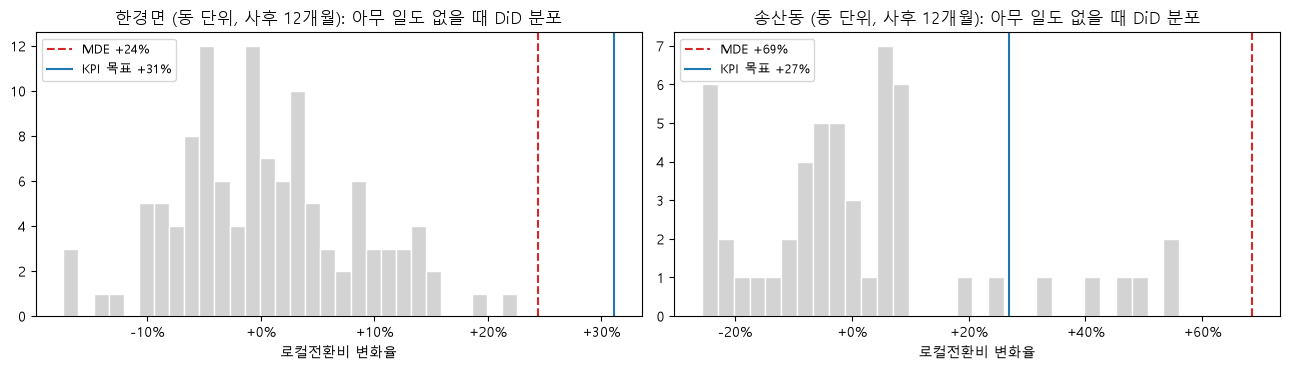


측정 계획: 사업 시작 전 12개월을 기준선으로, 시작 후 매월 이 노트북을 다시 돌려 타깃과 비교 동의 로컬전환비 격차 변화를 추적


In [33]:
PRE = 12
conv_m = (loc_m_all / attr_m).unstack()[list(T.index)]
LC = np.log(conv_m.where(conv_m > 0))
months_all = list(LC.index)

# 마을 단위 월별 로컬전환비 (관광지 도착 5천 건 이상 마을)
pm = p.assign(attr=np.where(p['그룹'].isin(ATTR_G), p['관광객도착'], 0), loc=np.where(p['그룹'].isin(LOCAL_G), p['관광객도착'], 0))
vm = pm.groupby(['월', '읍면동명', '핀단위'])[['attr', 'loc']].sum()
big_v = pin_all.index[pin_all['관광지도착'] >= 5000]
vm = vm[vm.index.droplevel(0).isin(big_v)]
LV = np.log((vm['loc'] / vm['attr']).where((vm['attr'] > 0) & (vm['loc'] > 0))).unstack([1, 2])

def did(s_t, s_c, start, post):
    i = months_all.index(start)
    gap = s_t - s_c
    pre_, post_ = gap.iloc[i - PRE:i], gap.iloc[i:i + post]
    if pre_.isna().sum() > 2 or post_.isna().sum() > 1 or len(post_) < post:
        return np.nan
    return post_.mean() - pre_.mean()

def placebo(mat, fakes, ctrl, post):
    starts = months_all[PRE:len(months_all) - post + 1]
    est = []
    for fk in fakes:
        cs = [c_ for c_ in ctrl if c_ != fk]
        c_mean = mat[cs].mean(axis=1)
        est += [did(mat[fk], c_mean, s_, post) for s_ in starts]
    return pd.Series(est).dropna()

mde_rows, placebo_all = [], {}
pass_v = [c_ for c_ in LV.columns if c_[0] in PASS]
for tgt in FINAL:
    ty = T.at[tgt, '유형']
    ctrl_d = [n for n in T.index[T['유형'] == ty] if n not in PASS]
    pool_d = [n for n in T.index[T['유형'] == ty] if n != tgt]
    pin_ = PIN.loc[tgt].sort_values('기준 대비 로컬 부족(도착 수)', ascending=False).index[0]
    ctrl_v = [c_ for c_ in LV.columns if c_ not in pass_v]
    goal_d = Y25.at[BENCH[tgt], '로컬전환비'] / Y25.at[tgt, '로컬전환비'] - 1
    goal_v = pin_q25 / PIN.at[(tgt, pin_), '로컬전환비'] - 1
    for post in (6, 12):
        for level, mat, fakes, ctrl, goal, unit in [('동', LC, pool_d, ctrl_d, goal_d, f'{tgt} 전체'),
                                                    ('핀포인트 마을', LV, ctrl_v, ctrl_v, goal_v, (f'{TGT_SPOT[tgt]["목적지명"]} 일대 마을' if pin_ in DONGS else f'{pin_} 마을'))]:
            est = placebo(mat, fakes, ctrl, post)
            if level == '동' and post == 12:
                placebo_all[tgt] = est
            mde = np.exp(2.8 * est.std()) - 1
            mde_rows.append({'타깃': tgt, '측정 단위': unit, '수준': level, '사후 기간(개월)': post, '플라시보 수': len(est),
                             'MDE': mde, 'KPI 목표 변화': goal, '검출 가능': goal >= mde})
MDE = pd.DataFrame(mde_rows)
print(MDE.round(2).to_string(index=False))
for tgt in FINAL:
    ok_ = MDE[(MDE['타깃'] == tgt) & MDE['검출 가능']]
    best = ok_.sort_values('사후 기간(개월)').iloc[0] if len(ok_) else None
    print(f"{tgt}: " + (f"{best['측정 단위']} 기준 {best['사후 기간(개월)']}개월이면 KPI 목표(+{best['KPI 목표 변화']:.0%})가 우연(MDE +{best['MDE']:.0%})과 구분됨"
                         if best is not None else '설계한 조합으로는 검출이 어려움'))

fig, ax = plt.subplots(1, len(FINAL), figsize=(6.5 * len(FINAL), 3.8), squeeze=False)
for i, tgt in enumerate(FINAL):
    e = placebo_all[tgt]
    r_ = MDE[(MDE['타깃'] == tgt) & (MDE['수준'] == '동') & (MDE['사후 기간(개월)'] == 12)].iloc[0]
    ax[0, i].hist(np.exp(e) - 1, bins=30, color='lightgray', edgecolor='white')
    ax[0, i].axvline(r_['MDE'], color='tab:red', ls='--', label=f"MDE +{r_['MDE']:.0%}")
    ax[0, i].axvline(r_['KPI 목표 변화'], color='tab:blue', label=f"KPI 목표 +{r_['KPI 목표 변화']:.0%}")
    ax[0, i].set_title(f'{tgt} (동 단위, 사후 12개월): 아무 일도 없을 때 DiD 분포')
    ax[0, i].set_xlabel('로컬전환비 변화율'); ax[0, i].legend(fontsize=9)
    ax[0, i].xaxis.set_major_formatter(plt.FuncFormatter(lambda v_, _: f'{v_:+.0%}'))
plt.tight_layout(); save(fig, '09_효과측정_플라시보.png'); plt.show()
MDE.to_csv(os.path.join(OUT_DIR, 'v5_효과측정_MDE.csv'), index=False, encoding='utf-8-sig')
print('\n측정 계획: 사업 시작 전 12개월을 기준선으로, 시작 후 매월 이 노트북을 다시 돌려 타깃과 비교 동의 로컬전환비 격차 변화를 추적')

## 11. 저장: 최종 테이블 + 월별 모니터링 지표
제안 실행 후 같은 지표를 매월 다시 계산하면 효과를 추적할 수 있다 (심사기준 '향후 지속 활용' 대응).

In [34]:
FINAL_COLS = ['시', '권역', '유형', '관광객비중', '공급규모', '자연체험비중', '합의점수', '상위K_정의수', '부트스트랩_상위K확률', '민감도_선정횟수', '연도순위_2023', '연도순위_2024', '연도순위_2025',
              '통과형', '유형내_Z', '로컬전환비', '로컬방문당소비', '도착당소비', '체류율', '원안MI']
T[FINAL_COLS].sort_values('합의점수', ascending=False).to_csv(os.path.join(OUT_DIR, 'v5_관광동_최종.csv'), encoding='utf-8-sig')
PAIRS.to_csv(os.path.join(OUT_DIR, 'v5_타깃_벤치마킹.csv'), index=False, encoding='utf-8-sig')
SCEN.to_csv(os.path.join(OUT_DIR, 'v5_기대효과_시나리오.csv'), index=False, encoding='utf-8-sig')

loc_m = p[p['그룹'].isin(LOCAL_G)].groupby(['월', '읍면동명'])['관광객도착'].sum()
mon = pd.DataFrame({'관광지_관광객도착': attr_m, '로컬_관광객도착': loc_m, '관광객소비_숙박제외': spend_m})
mon['로컬전환비'] = mon['로컬_관광객도착'] / mon['관광지_관광객도착']
mon['도착당소비'] = mon['관광객소비_숙박제외'] / mon['관광지_관광객도착']
watch = list(dict.fromkeys(FINAL + MONITOR + [BENCH[n] for n in FINAL + MONITOR]))
mon.loc[(slice(None), watch), :].reset_index().to_csv(os.path.join(OUT_DIR, 'v5_월별_모니터링지표.csv'), index=False, encoding='utf-8-sig')
print('저장 완료:', sorted(os.listdir(OUT_DIR)))

저장 완료: ['00_배경_연도추이.png', '01_통과형_합의점수.png', '02_관광환경_유형.png', '03_소비퍼널_분해.png', '04_월별_격차.png', '05_핀포인트_마을.png', '06_지도_통과형.png', '07_지도_서귀포시내.png', '08_스팟_공급연결진단.png', '09_효과측정_플라시보.png', 'v5_관광동_최종.csv', 'v5_기대효과_시나리오.csv', 'v5_스팟_벤치마킹.csv', 'v5_스팟_진단.csv', 'v5_액션플랜_KPI.csv', 'v5_월별_모니터링지표.csv', 'v5_타깃_벤치마킹.csv', 'v5_효과측정_MDE.csv', '카테고리_분류표.csv', '핀포인트_마을단위.csv']


## 12. 대시보드용 데이터 내보내기
웹 대시보드 「제주 통과형 진단」이 읽는 파일을 `outputs/v5/dashboard/`에 만든다. 새 데이터로 이 노트북을 다시 돌리면 대시보드 데이터도 같이 갱신된다.

In [35]:
DASH_DIR = os.path.join(OUT_DIR, 'dashboard')
os.makedirs(DASH_DIR, exist_ok=True)

role = pd.Series('-', index=DONGS)
role[[BENCH[n] for n in FINAL]] = '벤치마킹'
role[MONITOR] = '모니터링'
role[FINAL] = '최종 타깃'
dash_dong = pd.DataFrame({'읍면동명': DONGS})
dash_dong['시'] = dash_dong['읍면동명'].map(D['시'])
dash_dong['구분'] = np.where(dash_dong['읍면동명'].isin(ISLANDS), '도서(판정 제외)',
                         np.where(dash_dong['읍면동명'].isin(T.index), '관광 동', '생활권(판정 제외)'))
for col_ in ['유형', '합의점수', '민감도_선정횟수', '연도순위_2023', '연도순위_2024', '연도순위_2025', '로컬전환비', '로컬방문당소비', '도착당소비']:
    dash_dong[col_] = dash_dong['읍면동명'].map(T[col_])
dash_dong['관광객비중'] = dash_dong['읍면동명'].map(D['관광객비중'])
dash_dong['검증순위_2026H1'] = dash_dong['읍면동명'].map(H1_rank.iloc[:, -1])
dash_dong['통과형'] = dash_dong['읍면동명'].isin(PASS)
dash_dong['역할'] = dash_dong['읍면동명'].map(role)
dash_dong = dash_dong.round({'합의점수': 2, '로컬전환비': 2, '관광객비중': 3, '로컬방문당소비': 0, '도착당소비': 0})
dash_dong.to_csv(os.path.join(DASH_DIR, 'dongs.csv'), index=False, encoding='utf-8')

# 경계: 좌표를 소수 4자리(약 10m)로 줄여 파일 크기를 낮춤
bnd = [{'읍면동명': nm, 'rings': json.dumps([np.round(r, 4).tolist() for r in rings])} for nm, rings in shapes.items()]
json.dump(bnd, open(os.path.join(DASH_DIR, 'boundary.json'), 'w', encoding='utf-8'), ensure_ascii=False)

sp_out = DOM[['목적지명', '스팟종류', '읍면동명', '핀단위', '관광객도착', '로컬전환비', '로컬소비처수', '로컬밀도', '진단', '인접 상권(2km)']].copy()
sp_out['스팟ID'] = sp_out['목적지명'] + '|' + sp_out['핀단위']
sp_out = sp_out.merge(EXPAND[['목적지명', '핀단위', '비고']], on=['목적지명', '핀단위'], how='left')
sp_out = sp_out.merge(EXP_NT[['목적지명', '핀단위', '연 추가 소비_보수(억원)', '연 추가 소비_상한(억원)']], on=['목적지명', '핀단위'], how='left')
sp_out['비고'] = sp_out['비고'].fillna('-')
sp_out = sp_out.round({'로컬전환비': 2, '로컬소비처수': 0, '로컬밀도': 1, '연 추가 소비_보수(억원)': 0, '연 추가 소비_상한(억원)': 0})
sp_out.to_csv(os.path.join(DASH_DIR, 'spots.csv'), index=False, encoding='utf-8')

kpi_rows = []
for tgt in FINAL:
    ts_ = TGT_SPOT[tgt]
    pin_ = PIN.loc[tgt].sort_values('기준 대비 로컬 부족(도착 수)', ascending=False).index[0]
    upa_now_ = Y25.at[tgt, SPEND] / Y25.at[tgt, '관광지_관광객도착']
    upa_goal_ = (Y25.at[tgt, SPEND] + 0.5 * max(Y25.at[tgt, '기대소비'] - Y25.at[tgt, SPEND], 0)) / Y25.at[tgt, '관광지_관광객도착']
    bm_ = BENCH[tgt]
    conv_goal_ = Y25.at[bm_, '로컬전환비'] if Y25.at[bm_, '로컬전환비'] > Y25.at[tgt, '로컬전환비'] else \
        Y25.loc[T.index[T['유형'] == T.at[tgt, '유형']], '로컬전환비'].median()
    kpi_rows += [
        {'타깃': tgt, '지표': '동 로컬전환비', '현재': Y25.at[tgt, '로컬전환비'], '목표': conv_goal_, '기준': f'벤치마킹 {bm_} 수준'},
        {'타깃': tgt, '지표': '관광지 도착당 소비(천원)', '현재': upa_now_ / 1e3, '목표': upa_goal_ / 1e3, '기준': '기대 소비 격차 50% 해소'},
        {'타깃': tgt, '지표': f'{ts_["목적지명"]} 마을 로컬전환비', '현재': PIN.at[(tgt, pin_), '로컬전환비'], '목표': pin_q25, '기준': '제주 마을 하위 25% 선'},
    ]
kpi_df = pd.DataFrame(kpi_rows)
is_won = kpi_df['지표'].str.contains('천원')
kpi_df.loc[is_won, ['현재', '목표']] = kpi_df.loc[is_won, ['현재', '목표']].round(0)
kpi_df.loc[~is_won, ['현재', '목표']] = kpi_df.loc[~is_won, ['현재', '목표']].round(2)
kpi_df.to_csv(os.path.join(DASH_DIR, 'kpi.csv'), index=False, encoding='utf-8')

act_out = ACTION.reset_index()[['타깃', '유형', '벤치마킹', '핵심 스팟·진단', '스팟 벤치마킹(같은 종류)', '새는 업종', '취약 시기', '제안 액션']]
act_out = act_out.merge(SCEN[SCEN['방식'].str.startswith('A')].groupby('타깃')['추가 소비(억원/년)'].agg(기대소비_하한='min', 기대소비_상한='max').reset_index(), on='타깃')
act_out.round(0).to_csv(os.path.join(DASH_DIR, 'actions.csv'), index=False, encoding='utf-8')

mon_out = mon.loc[(slice(None), watch), ['로컬전환비', '도착당소비']].reset_index()
mon_out['월'] = pd.to_datetime(mon_out['월'].astype(str), format='%Y%m').dt.strftime('%Y-%m-01')
mon_out['도착당소비'] = mon_out['도착당소비'] / 1e3
mon_out['역할'] = mon_out['읍면동명'].map(role)
mon_out.round(3).to_csv(os.path.join(DASH_DIR, 'monthly.csv'), index=False, encoding='utf-8')

bg = yr_tbl.reset_index().rename(columns={'월': '연도'})
bg['관광지도착당_소비'] = bg['관광지도착당_소비'] / 1e3
bg[['연도', '차량도착', '관광지_관광객도착', 'SKT관광객방문', '관광지도착당_소비']].round(1).to_csv(
    os.path.join(DASH_DIR, 'background.csv'), index=False, encoding='utf-8')
kc = ksel[ksel['변수세트'].str.startswith('C') & (ksel['k'] == K)].iloc[0]
pd.DataFrame([
    {'지표': '로컬 방문 탄력성', '값': LEVER.iloc[0, 0]},
    {'지표': '로컬 방문 탄력성 p값', '값': LEVER.iloc[0, 3]},
    {'지표': '군집 실루엣', '값': kc['실루엣']},
    {'지표': '군집 부트스트랩 ARI', '값': kc['부트스트랩ARI']},
    {'지표': '관광 동 수', '값': len(T)},
    {'지표': '분석 스팟 수', '값': len(DOM)},
    {'지표': '스팟 로컬전환비 중앙값', '값': CONV_MED},
    {'지표': '제주 마을 로컬전환비 중앙값', '값': ref_pin},
]).round(3).to_csv(os.path.join(DASH_DIR, 'model.csv'), index=False, encoding='utf-8')
print('대시보드 파일:', {f_: os.path.getsize(os.path.join(DASH_DIR, f_)) for f_ in sorted(os.listdir(DASH_DIR))})

대시보드 파일: {'actions.csv': 1562, 'background.csv': 212, 'boundary.json': 206661, 'dongs.csv': 4807, 'kpi.csv': 541, 'model.csv': 269, 'monthly.csv': 10412, 'spots.csv': 6681}
